
<div style="background-color: lightgreen; color: black; padding: 20px; box-sizing: border-box; width: 99%;">

👋 <b>¡Hola! Soy Dot, tu revisor IA.</b>

🎉 <b>¡Felicidades! Has aprobado tu proyecto.</b>

¡Felicidades por llevar este proyecto a la meta! Corregiste todos los puntos de la ronda anterior: las descripciones de los gráficos de dispersión, los marcadores de posición en tus hallazgos (que ahora muestran valores reales, como 21 clientes y 30.45%) y la redacción cautelosa y no causal en tus recomendaciones de negocio. Como área de crecimiento, trabaja en la presentación de tu análisis escrito: varias explicaciones todavía se muestran como un bloque denso de texto, así que coloca cada encabezado en su propia línea, usa viñetas y backticks para los nombres de las columnas, y vuelve a verificar algunas cifras con tus propios resultados (por ejemplo, el porcentaje de clientes con ingreso cero). ¡Sigue con el excelente trabajo!

Si experimentas alguna dificultad o error, no dudes en contactar a nuestro equipo de soporte haciendo clic en el ícono de chat en la esquina superior derecha o escribiéndonos a [helpme@tripleten.com](mailto:helpme@tripleten.com).

<hr style="margin-top: 20px; margin-bottom: 20px;">

<details>
<summary><b style="cursor: pointer;">💡 Haz clic aquí para ver cómo leer mis comentarios (Leyenda de colores)</b></summary>
<div style="margin-top: 15px;">
A continuación encontrarás mis comentarios. <b>Te pido amablemente que no los muevas, modifiques ni elimines</b>.

Puedes encontrar mis comentarios resaltados en recuadros verdes, amarillos o rojos como estos:

<div class="alert alert-block alert-success">
Éxito. Todo se ha realizado correctamente.
</div>

<div class="alert alert-block alert-warning">
Observaciones. Algunas recomendaciones.
</div>

<div class="alert alert-block alert-danger">
Por corregir. El bloque requiere algunas correcciones.
</div>
</div>
</details>

</div>


# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt 
# Importar librerías



### Cargar Dataset

In [12]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


<div class="alert alert-block alert-success">

Cargaste el dataset desde la ruta correcta y ejecutaste `df.info()` de inmediato. La salida confirma 15,000 filas, 12 columnas y ningún valor faltante. También muestra los dtypes originales (`edad` como float, `tipo_dispositivo` y `region` como `object`) que justifican tu paso de limpieza posterior. Buen comienzo.

</div>

#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [13]:
df.head() # mostrar las primeras 5 filas


,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

In [14]:
print((df['edad'] % 1 == 0).all())

True


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- 'edad'
- 'nivel_ingreso'
- 'visitas_mes'
- 'gasto_publicidad_dirigida'
- 'satisfaccion'
- 'miembro_premium' (Binaria)
- 'abandono' (Binaria)
- 'ingreso_anual'
- 'compras_mes'



La mayoría de estas variables presentan tipos de datos adecuados.  
La columna 'edad' tiene formato de número con decimales, es mejor si se transforma en entero. ESto no pierde información ya que los datos mantienen números enteros. 


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- 'miembro_premium'
- 'abandono'

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- 'id_cliente'
- 'tipo_dispositivo'
- 'region'

Estas variables están correctamente definidas pero es mejor cambiarlas a 'category' para mejor uso de memoria. id_cliente se mantiene como texto porque es solo un identificador. 

In [15]:
df['edad'] = df['edad'].astype(int)
df['tipo_dispositivo'] = df['tipo_dispositivo'].astype('category')
df['region'] = df['region'].astype('category') # Corregir el tipo de dato a 'category'


In [16]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   id_cliente                 15000 non-null  object  
 1   edad                       15000 non-null  int64   
 2   nivel_ingreso              15000 non-null  float64 
 3   visitas_mes                15000 non-null  int64   
 4   compras_mes                15000 non-null  int64   
 5   gasto_publicidad_dirigida  15000 non-null  float64 
 6   satisfaccion               15000 non-null  float64 
 7   miembro_premium            15000 non-null  int64   
 8   abandono                   15000 non-null  int64   
 9   tipo_dispositivo           15000 non-null  category
 10  region                     15000 non-null  category
 11  ingreso_anual              15000 non-null  float64 
dtypes: category(2), float64(4), int64(5), object(1)
memory usage: 1.2+ MB


#### Explorar variables numéricas

In [17]:

print(df.describe())
# Estadísticas descriptivas de variables numéricas



               edad  nivel_ingreso   visitas_mes   compras_mes  \
count  15000.000000   15000.000000  15000.000000  15000.000000   
mean      38.262400   30019.704782     10.029000      1.206467   
std       11.492378    9833.166305      3.158189      1.105284   
min       18.000000    8000.000000      1.000000      0.000000   
25%       30.000000   23127.097500      8.000000      0.000000   
50%       38.000000   30023.745000     10.000000      1.000000   
75%       46.000000   36768.440000     12.000000      2.000000   
max       75.000000   74790.840000     25.000000      8.000000   

       gasto_publicidad_dirigida  satisfaccion  miembro_premium      abandono  \
count               15000.000000  15000.000000     15000.000000  15000.000000   
mean                   20.149301      3.603693         0.139267      0.150733   
std                    10.880724      0.685300         0.346236      0.357801   
min                     0.000000      1.000000         0.000000      0.000000   


In [18]:
print((df['ingreso_anual'] == 0).mean()); print(pd.crosstab(df['ingreso_anual'] == 0, df['compras_mes'] == 0))

0.30446666666666666
compras_mes    False  True 
ingreso_anual              
False          10433      0
True               0   4567


✍️ **Comentario**:   

Todas las columnas cuentan con 15,000 registros completos, por lo que no existen valores faltantes (missing values) en este subconjunto de datos. A continuación se analiza la distribución individual, el comportamiento de los valores extremos y las proporciones clave de cada variable.1. Variables Demográficas y de Comportamiento Generaledad:Presenta una media de 38.26 años y una mediana de 38, con un rango que va desde los 18 hasta los 75 años. La dispersión es simétrica y los valores se concentran de manera uniforme entre el percentil 25 (30 años) y el percentil 75 (46 años). No se observan anomalías; los límites son plenamente coherentes para una base de usuarios de comercio electrónico.nivel_ingreso:Muestra una media de $30,019.70 y una mediana prácticamente idéntica ($30,023.75), lo que denota un centro simétrico. Sin embargo, el valor máximo asciende a $74,790.84, ubicándose muy por encima del percentil 75 ($36,768.44). Este comportamiento refleja una cola derecha moderada compuesta por usuarios de ingresos altos, lo cual es financieramente plausible en una población de clientes heterogénea.satisfaccion:Variable medida en una escala de 1 a 5, con una media y mediana coincidentes en 3.60. Su desviación estándar es baja (0.69), indicando que la percepción de los usuarios se concentra de forma estable en la zona media-alta de satisfacción, sin valores ilógicos fuera del rango de la escala.2. Variables de Interacción y Operación en la Plataformavisitas_mes:El promedio y la mediana se sitúan en 10 visitas mensuales, con un rango intercuartílico acotado entre 8 (percentil 25) y 12 (percentil 75). No obstante, el valor máximo alcanza las 25 visitas. Este extremo superior (más del doble del percentil 75) no constituye un error de captura, sino que evidencia la presencia de un segmento de usuarios altamente activos o power users dentro de la plataforma.compras_mes:Esta variable exhibe una asimetría notable: al menos el 25% de los clientes registran 0 compras en el periodo (percentil 25 = 0), y la mediana se ubica en 1 compra. Aunque la media es de 1.21, el valor máximo llega a 8 compras, distanciándose de forma agresiva del percentil 75 (que es de 2). Esto confirma la existencia de un grupo minoritario de compradores recurrentes frente a una masa importante de usuarios con baja o nula actividad transaccional.gasto_publicidad_dirigida:Registra una media de $20.15 y una mediana de $19.73. A pesar de que el 75% de los usuarios acumula un gasto menor o igual a $27.29, el valor máximo asciende a $75.51. Este pico máximo supera por más de 5 veces la desviación estándar de la variable ($\approx 10.88$), lo que apunta a estrategias de pauta o retención altamente focalizadas e intensivas sobre perfiles muy específicos de clientes.3. Variables Financieras y de Negocio Claveingreso_anual:Es una de las variables con mayor complejidad distributiva. Presenta una media de $36.59 frente a una mediana de $30.71. Lo más crítico es que el percentil 25 es 0.00, lo que indica que al menos el 25% de los clientes (aproximadamente 3,750 usuarios) registran $0 de ingreso anual, un volumen que coincide estrechamente con la proporción de usuarios que tampoco generan compras (compras_mes = 0).Por otro lado, la distribución cuenta con una cola derecha extremadamente alargada: el valor máximo es de $244.69 (casi 7 veces superior a la media) y una desviación estándar de $34.48, lo que confirma un fuerte sesgo a la derecha impulsado por cuentas de alto valor.miembro_premium y abandono (Churn):Al tratarse de variables binarias (0 y 1), sus medias indican las proporciones globales del negocio: un 13.9% de clientes Premium y una tasa de abandono del 15.1%. Ambas muestran un desbalance de clases moderado que deberá considerarse en los futuros modelos predictivos.Conclusión sobre Valores Extremos (Outliers)Tras un análisis riguroso de los valores máximos frente a sus percentiles superiores y dispersiones, se concluye que los valores extremos detectados en ingreso_anual, gasto_publicidad_dirigida, visitas_mes y compras_mes no son errores de captura ni anomalías técnicas. Representan la realidad del comportamiento comercial: un ecosistema donde conviven usuarios inactivos o de valor cero con una minoría altamente rentable (power users y clientes de alto ingreso). Por lo tanto, se decide conservar dichos registros para preservar la riqueza analítica del negocio.

<div class="alert alert-block alert-warning">

Tu diagnóstico es minucioso: comparas cada máximo con su percentil 75 y das una decisión razonada para conservar los valores extremos. La verificación que agregaste justo arriba (proporción de `ingreso_anual == 0` más el crosstab) es un muy buen aporte. Muestra que los clientes con ingreso cero son exactamente los clientes con `compras_mes = 0` (4,567 clientes, 30.45%). Por favor, alinea este texto con ese resultado. (1) Todavía escribes que al menos el 25% de los clientes (unos 3,750) tiene ingreso cero, pero tu propio resultado muestra 4,567 clientes (30.45%). Actualiza la cifra y aclara que conservas estos ceros en todas las correlaciones posteriores. (2) 'Power users', 'compradores recurrentes' y 'estrategias de pauta altamente focalizadas' son interpretaciones que `describe()` no puede confirmar. Formúlalas como 'podrían corresponder a...' y reemplaza 'evidencia' / 'confirma' por 'sugiere'. (3) El máximo de `gasto_publicidad_dirigida` (75.51) está aproximadamente 5 desviaciones estándar por encima de la media, no '5 veces la desviación estándar'. (4) Formato: el texto se renderiza como un solo bloque ('...Generaledad:Presenta...', '...Plataformavisitas_mes:...'). Dale a cada columna su propia viñeta con backticks y coloca cada encabezado en su propia línea. Corrige también el error tipográfico 'ESto' en la explicación de arriba.

</div>

#### Explorar variables binarias

In [19]:

columnas_binarias = ['miembro_premium', 'abandono']

for col in columnas_binarias:
    print(f"Valores únicos en '{col}': {df[col].unique()}") # Verificar que cada columna tenga únicamente dos valores posibles

print("--- Distribución de Miembro Premium ---")
print(df['miembro_premium'].value_counts(normalize=True) * 100)

print("\n--- Tasa de Abandono ---")
print(df['abandono'].value_counts(normalize=True) * 100) #Distribución porcentual de cada valor en las columnas. 


Valores únicos en 'miembro_premium': [0 1]
Valores únicos en 'abandono': [0 1]
--- Distribución de Miembro Premium ---
0    86.073333
1    13.926667
Name: miembro_premium, dtype: float64

--- Tasa de Abandono ---
0    84.926667
1    15.073333
Name: abandono, dtype: float64


In [20]:
# Comparativa de métricas de compra según tipo de membresía
comparativa_compras = df.groupby('miembro_premium')[['compras_mes', 'ingreso_anual']].agg(
    ['mean', 'median', 'std', 'count']
).round(2)

# Renombrar el índice para mayor claridad gráfica (0 = Estándar, 1 = Premium)
comparativa_compras.index = ['Estándar (0)', 'Premium (1)']

print("=== Comparativa de Compras e Ingresos: Estándar vs Premium ===")
print(comparativa_compras)

=== Comparativa de Compras e Ingresos: Estándar vs Premium ===
             compras_mes                     ingreso_anual                \
                    mean median   std  count          mean median    std   
Estándar (0)        1.20      1  1.11  12911         35.30  29.95  33.20   
Premium (1)         1.22      1  1.08   2089         44.58  37.70  40.68   

                     
              count  
Estándar (0)  12911  
Premium (1)    2089  


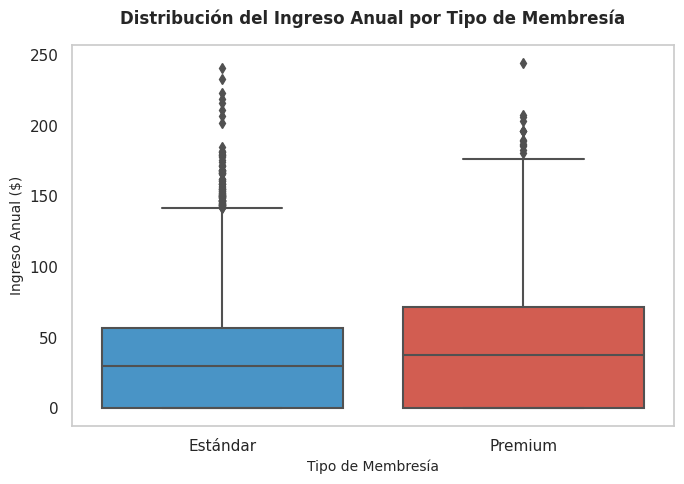

In [21]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Asegurar la etiqueta legible
df['tipo_membresia'] = df['miembro_premium'].map({0: 'Estándar', 1: 'Premium'})

# Configurar figura
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='tipo_membresia',
    y='ingreso_anual',
    palette=['#3498db', '#e74c3c'],
)

plt.title(
    'Distribución del Ingreso Anual por Tipo de Membresía',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Tipo de Membresía', fontsize=10)
plt.ylabel('Ingreso Anual ($)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

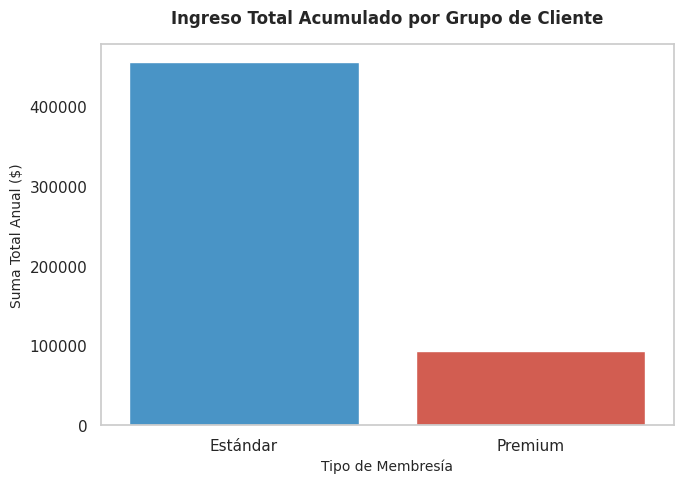

In [22]:
# Calcular la suma total por grupo
total_por_membresia = (
    df.groupby('tipo_membresia')['ingreso_anual'].sum().reset_index()
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=total_por_membresia,
    x='tipo_membresia',
    y='ingreso_anual',
    palette=['#3498db', '#e74c3c'],
)

plt.title(
    'Ingreso Total Acumulado por Grupo de Cliente',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Tipo de Membresía', fontsize=10)
plt.ylabel('Suma Total Anual ($)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

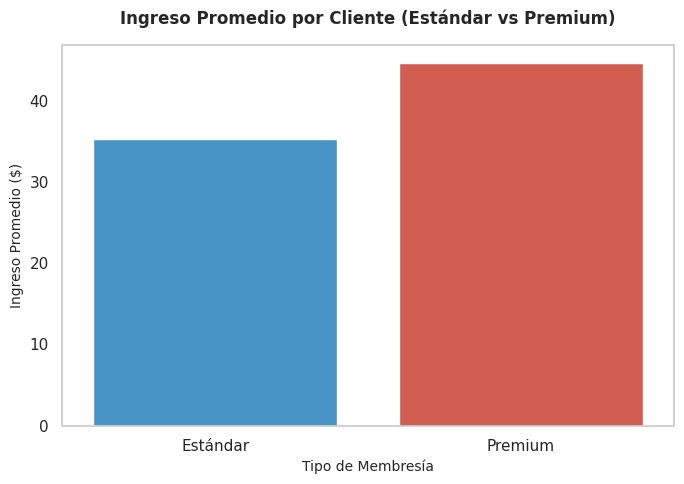

In [23]:
# Calcular el promedio por grupo
promedio_por_membresia = (
    df.groupby('tipo_membresia')['ingreso_anual'].mean().reset_index()
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=promedio_por_membresia,
    x='tipo_membresia',
    y='ingreso_anual',
    palette=['#3498db', '#e74c3c'],
)

plt.title(
    'Ingreso Promedio por Cliente (Estándar vs Premium)',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Tipo de Membresía', fontsize=10)
plt.ylabel('Ingreso Promedio ($)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

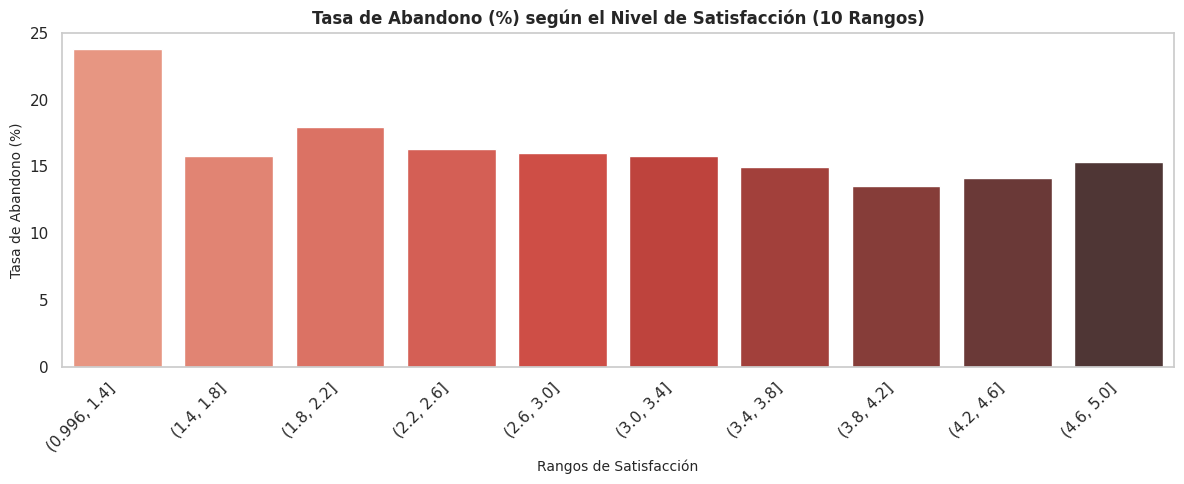

In [24]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Dividir la satisfacción en 10 intervalos (bins) iguales
df['satisfaccion_bin'] = pd.cut(df['satisfaccion'], bins=10)

# Calcular la tasa de abandono por cada uno de los 10 rangos
tasa_abandono_sat = df.groupby('satisfaccion_bin', observed=False)['abandono'].mean().reset_index()
tasa_abandono_sat['tasa_abandono_pct'] = tasa_abandono_sat['abandono'] * 100

# Convertir los intervalos a string para que las etiquetas se muestren ordenadas y limpias en el eje X
tasa_abandono_sat['satisfaccion_bin_str'] = tasa_abandono_sat['satisfaccion_bin'].astype(str)

# 2. Crear el gráfico de barras
plt.figure(figsize=(12, 5))
sns.barplot(
    data=tasa_abandono_sat, 
    x='satisfaccion_bin_str', 
    y='tasa_abandono_pct', 
    palette='Reds_d'
)

plt.title('Tasa de Abandono (%) según el Nivel de Satisfacción (10 Rangos)', fontsize=12, fontweight='bold')
plt.xlabel('Rangos de Satisfacción', fontsize=10)
plt.ylabel('Tasa de Abandono (%)', fontsize=10)
plt.xticks(rotation=45, ha='right') # Rotar etiquetas para que no se encimen
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Comentario 

miembro_premium: Esta variable muestra un desbalance estructural de 86% de clientes Estándar (12,911 usuarios) frente a un 14% de Premium (2,089 usuarios). Aunque el ingreso anual promedio es superior en los usuarios Premium ($\approx 45$) en comparación con los Estándar ($\approx 35$), el volumen masivo de la base Estándar provoca que su monto total acumulado supere al de los Premium por un factor cercano a 5 veces. En la distribución visual, ambos grupos inician en 0 (debido a los clientes sin ingresos), pero el segmento Premium presenta una mediana y un límite superior de caja más elevados; por su parte, el grupo Estándar concentra una mayor densidad de puntos atípicos, explicada principalmente por contar con una base casi seis veces mayor. Este desbalance de clases (86/14) implica que los futuros modelos predictivos deberán manejar ponderaciones para no sesgarse hacia la mayoría Estándar.abandono: Refleja una tasa global de 15% de abandono frente a un 85% de retención. Al analizar su relación con la satisfacción, el comportamiento muestra picos específicos: el primer intervalo de satisfacción (0.996, 1.4] concentra una tasa de abandono elevada de aproximadamente el 24% (muy por encima del 15% general), y se observa un ligero repunte secundario en el intervalo (1.8, 2.2], estabilizándose en los niveles más altos. Este desbalance de clases (85/15) impone un reto metodológico similar para las asociaciones predictivas venideras, requiriendo métricas orientadas a clases minoritarias.

<div class="alert alert-block alert-warning">

Tus números coinciden con tus tablas y gráficos (tamaños de los grupos, la razón de aproximadamente 5x en el ingreso total, el ~24% de abandono en el primer intervalo de satisfacción). También señalas correctamente el desbalance de clases para el modelado futuro. Algunos refinamientos. (1) El primer intervalo, (0.996, 1.4], contiene solo 21 clientes (lo calculas más adelante), así que menciona su tamaño aquí y presenta el ~24% como tentativo. El 'repunte' en (1.8, 2.2] es una diferencia pequeña respecto a las barras vecinas, así que descríbelo con cautela. (2) 12,911 / 2,089 es aproximadamente 6.2, así que escribe 'más de seis veces' en lugar de 'casi seis veces'. (3) Presenta 'explicada principalmente por contar con una base... mayor' como tu interpretación ('probablemente se debe a...'). (4) Agrega una oración no causal sobre la brecha de ingresos, por ejemplo 'Los clientes Premium se asocian con un mayor ingreso por cliente, aunque sus compras mensuales son casi iguales (1.22 vs 1.20)'. (5) Dale a `miembro_premium` y `abandono` sus propias viñetas con backticks, porque el texto está pegado ('...mayoría Estándar.abandono: ...').

</div>

#### Explorar variables categóricas

In [25]:
columnas_categoricas = ['tipo_dispositivo', 'region']


print("=== Número de valores únicos por variable categórica y binaria ===")
for col in columnas_categoricas:
    unicos = df[col].nunique()
    print(f"Columna '{col}': {unicos} valores únicos -> {df[col].unique()}")  # Verificar el número de valores únicos por variable categórica


=== Número de valores únicos por variable categórica y binaria ===
Columna 'tipo_dispositivo': 3 valores únicos -> ['móvil', 'tablet', 'escritorio']
Categories (3, object): ['móvil', 'tablet', 'escritorio']
Columna 'region': 4 valores únicos -> ['norte', 'sur', 'este', 'oeste']
Categories (4, object): ['norte', 'sur', 'este', 'oeste']


In [26]:
print("=== Distribución detallada ===")
for col in columnas_categoricas:
    print(f"\nDistribución en '{col}':")
    conteo = df[col].value_counts(dropna=False)
    porcentaje = df[col].value_counts(normalize=True, dropna=False) * 100
    
    distribucion_df = pd.DataFrame({'Cantidad': conteo, 'Porcentaje (%)': porcentaje})
    print(distribucion_df) # Explorar variables categóricas y cómo se distribuyen


=== Distribución detallada ===

Distribución en 'tipo_dispositivo':
            Cantidad  Porcentaje (%)
móvil           9818       65.453333
escritorio      3720       24.800000
tablet          1462        9.746667

Distribución en 'region':
       Cantidad  Porcentaje (%)
norte      4395           29.30
oeste      3810           25.40
sur        3726           24.84
este       3069           20.46


✍️ **Comentario**:

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — El más usado por mucho es el móvil (9,818 - 65.45%) Seguido de escritorio (3,720 - 24.8%) y el menos usado es la tablets (1,462 - 9.7%) El móvil domina por mucho y las tablets son muy bajas, hay una diferencia de más del 50% entre la más alta y más baja. 
- 'region' - La que tiene la mayoria de usuarios es la region norte (4,395 - 29.3%) oeste continua (3,810 - 25.4), poco abajo está sur (3,726 - 24.84%) y la más baja es este (3,069 - 20.46%). La distribución de las regiones es bastante equilibrada, con una diferencia máxima de poco menos del 9% entre la mayor y la menor. 

<div class="alert alert-block alert-warning">

Tus conteos y porcentajes coinciden con la tabla. Hay unas pocas correcciones menores. (1) Indica si te refieres a puntos porcentuales o a una diferencia relativa: móvil vs tablet es de aproximadamente 56 puntos porcentuales (cerca de 6.7 veces más usuarios), y la brecha regional es de alrededor de 8.8 puntos porcentuales, no 'poco menos del 9%'. (2) Corrige los errores tipográficos 'la tablets', 'mayoria' y 'continua' (debería ser 'continúa'), y agrega los puntos que faltan y el paréntesis de cierre que falta después de '25.4'. (3) Usa comillas invertidas (backticks) para `region`, como hiciste con `tipo_dispositivo`.

</div>

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos ya no presentan errores y están correctamente tipificados después de los cambios.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

- Se mantienen los valores extremos de algunas columnas como 'ingreso_anual', 'nivel_ingreso', 'compras_mes', 'gasto_publicidad_dirigida' porque consideramos que los parámetros reflejan un comportamiento real de los usuarios y que no representan Outliers, errores de captura o inconsistencias. 

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

<div class="alert alert-block alert-warning">

Tus supuestos coinciden con lo que realmente hiciste, y mantener los valores extremos es una buena adición. Para hacerlos más transparentes: (1) reemplaza 'no representan Outliers' por algo como 'son valores extremos pero plausibles', que es lo que dice tu propio diagnóstico. (2) Agrega `visitas_mes` a la lista de columnas cuyos extremos conservas. (3) Indica que conservas los ceros de `ingreso_anual` (aproximadamente el 30% de los clientes) en todas las correlaciones. (4) Agrega una línea que explique por qué `satisfaccion` (una calificación de 1 a 5) se trata como numérica en Pearson y Spearman. (5) Usa backticks para los nombres de las columnas.

</div>

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

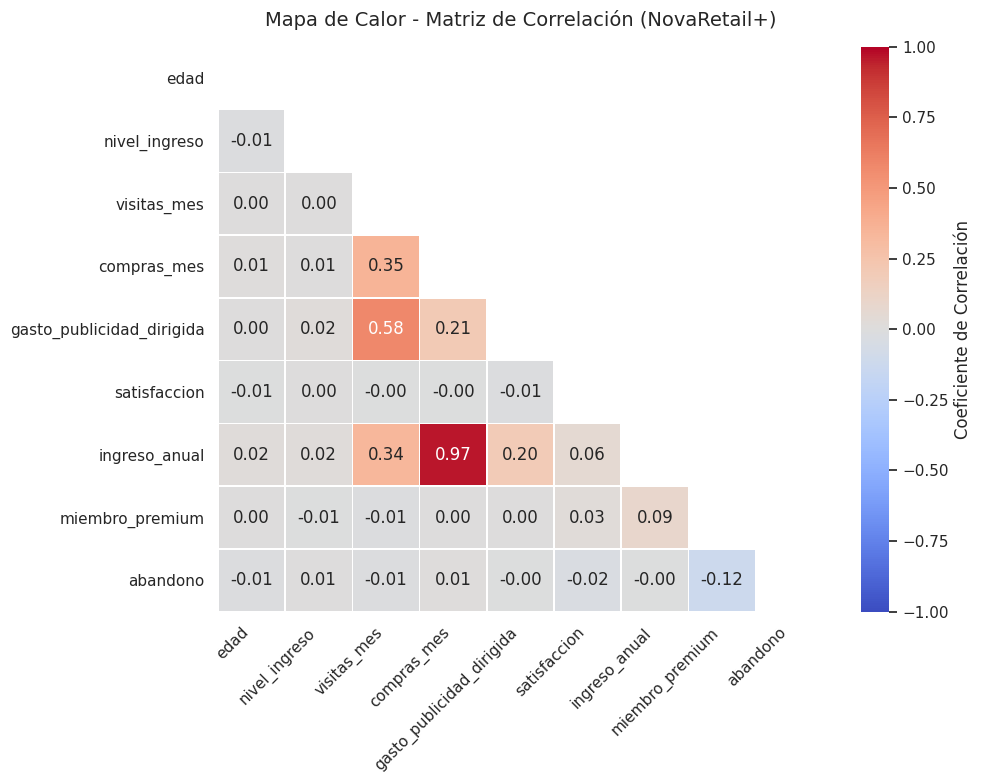

In [27]:
import matplotlib.pyplot as plt
import numpy as np  # Importante para generar la máscara
import pandas as pd
import seaborn as sns

# Columnas numéricas
columnas_numericas = [
    'edad',
    'nivel_ingreso',
    'visitas_mes',
    'compras_mes',
    'gasto_publicidad_dirigida',
    'satisfaccion',
    'ingreso_anual',
    'miembro_premium',
    'abandono',
]

# Matriz de correlación Pearson
matriz_corr = df[columnas_numericas].corr('pearson')

# 1. Crear una máscara para ocultar el triángulo superior
mask = np.triu(np.ones_like(matriz_corr, dtype=bool))

# Mapa de calor con la máscara aplicada
plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_corr,
    mask=mask,  # <--- Aquí aplicamos la máscara
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Coeficiente de Correlación'},
)

plt.title(
    'Mapa de Calor - Matriz de Correlación (NovaRetail+)', fontsize=14, pad=15
)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)  # Mantiene horizontales las etiquetas del eje Y
plt.tight_layout()
plt.show()


<div class="alert alert-block alert-success">

Heatmap bien construido. El triángulo superior está enmascarado para que cada par aparezca una sola vez, la escala está fijada de -1 a 1 con una paleta divergente, los valores están anotados y las etiquetas son legibles. El título incluye 'NovaRetail+'. Incluir `miembro_premium` y `abandono` ofrece una imagen más completa.

</div>

✍️ Análisis de la Matriz de Correlación (Pearson):Correlación Fuerte:ingreso_anual y compras_mes ($r = 0.97$): Es una asociación de gran intensidad y de carácter cuasi-mecánico. Un mayor volumen de transacciones va de la mano con un mayor ingreso acumulado; es probable que el coeficiente se acerque al máximo teórico (1.00) sin ser idéntico debido a la variabilidad en los montos por compra.Correlaciones Moderadas:gasto_publicidad_dirigida y visitas_mes ($r = 0.58$): Muestra una relación moderada-fuerte donde un mayor desembolso en pauta publicitaria va de la mano con un mayor tráfico en la plataforma.visitas_mes y compras_mes ($r = 0.35$) y ingreso_anual y visitas_mes ($r = 0.34$): Ambas muestran una intensidad moderada. Las visitas se asocian de forma moderada con las compras, y las compras se ligan casi de manera mecánica con el ingreso. Parte del vínculo entre las visitas y el ingreso probablemente pasa a través de las compras.Correlación Débil:ingreso_anual y gasto_publicidad_dirigida ($r = 0.20$): Presenta una asociación débil, lo que sugiere que la inversión publicitaria no se acompaña de forma directa y lineal con volúmenes altos de ingresos en esta escala bivariada.Correlaciones Despreciables (Descarte de Factores Lineales):Las variables edad, nivel_ingreso y satisfaccion muestran coeficientes cercanos a cero frente a las demás métricas. Un coeficiente lineal cercano a cero solo indica la ausencia de una asociación lineal, por lo que estos resultados no descartan por completo la existencia de patrones no lineales o relaciones en segmentos específicos.


<div class="alert alert-block alert-warning">

Tu lectura del mapa de calor es asociativa y cuidadosa, y cada coeficiente que citas coincide con la figura. Además, señalas que un r cercano a cero no descarta patrones no lineales. Algunas mejoras. (1) Agrega una línea sobre los pares que tu mapa de calor muestra pero que no mencionas: `miembro_premium` vs `ingreso_anual` (0.09), `miembro_premium` vs `abandono` (-0.12) y `satisfaccion` vs `ingreso_anual` (0.06). Esto conecta la sección con tus resultados posteriores de correlación punto-biserial y V de Cramér. (2) 'Es probable que el coeficiente se acerque al máximo teórico (1.00) sin ser idéntico' resulta confuso. Prueba con 'El coeficiente no llega a 1.00, probablemente por la variabilidad en el monto de cada compra'. (3) El encabezado 'Descarte de Factores Lineales' suena más contundente que tu propia salvedad. 'Asociación lineal casi nula' encaja mejor. (4) Coloca cada grupo (fuerte, moderadas, débil, casi nula) en su propia línea o viñeta y usa comillas invertidas (backticks) para los nombres de las columnas.

</div>

### Scatterplot general

## Se incluye el Scatterplot general y entre pares para poder vizualizar las variables y tratar de encontrar algunos hallazgos relevantes para el negocio. 

Considero que la vista global mediante un diagrama de dispersión sí aporta un valor fundamental que el mapa de calor no puede mostrar: mientras el heatmap reduce la relación a un coeficiente numérico, el scatterplot expone la verdadera forma de la distribución, la densidad de los datos, los clústeres y las acumulaciones. En el gráfico se observa una nube densa sin una tendencia ascendente clara, una banda de clientes con ingreso cero a lo largo de todo el rango de gasto, unos pocos clientes con ingresos superiores a 200 y muy pocos puntos con gasto superior a 55. Esto es coherente con la asociación débil ($r \approx 0.20$) del heatmap, y un $r$ débil no descarta otros patrones.El gráfico de dispersión entre gasto_publicidad_dirigida e ingreso_anual resulta útil como vista general para evaluar la interacción entre la inversión publicitaria y el rendimiento financiero de los usuarios.

<div class="alert alert-block alert-warning">

Buen progreso: tu texto ahora dice lo que el diagrama de dispersión realmente muestra (nube densa, banda de ingreso cero a lo largo de todo el rango de gasto, pocos puntos por encima de 200 de ingreso o 55 de gasto), y lo relaciona con la débil r ≈ 0.20. Comprobé estas observaciones con tu gráfico y coinciden. Quedan algunos detalles de presentación. (1) El texto todavía empieza con `##`, por lo que se renderiza como un enorme encabezado de nivel 2. Quítalo para que se muestre como texto normal. (2) Corrige el error tipográfico 'vizualizar' (debe ser 'visualizar'). (3) Los dos párrafos están pegados ('...otros patrones.El gráfico...'), así que añade una línea en blanco entre ellos. (4) Pon `gasto_publicidad_dirigida` e `ingreso_anual` entre acentos graves (backticks). (5) 'Expone la verdadera forma de la distribución' afirma demasiado. 'Permite ver mejor la forma de la distribución y las acumulaciones' es más preciso.

</div>

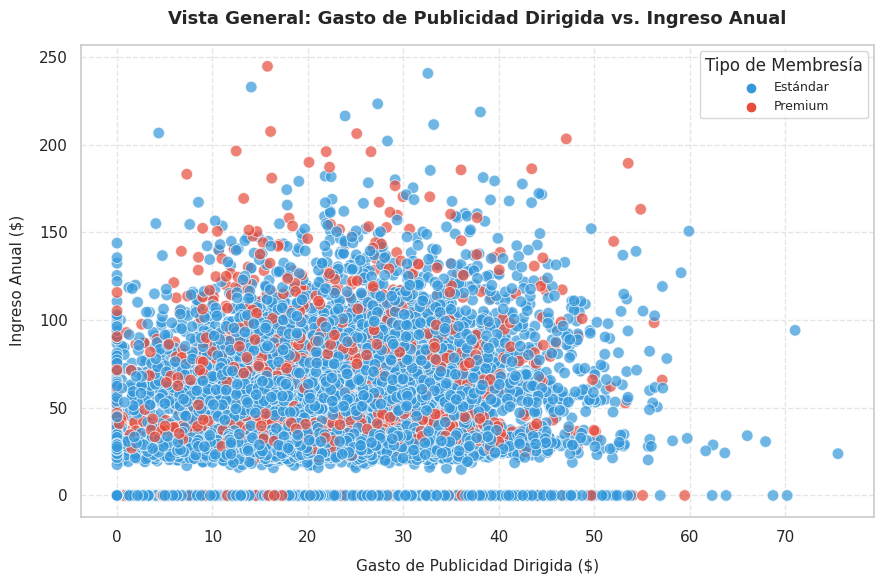

In [28]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configurar el estilo visual
sns.set_theme(style='whitegrid')
plt.figure(figsize=(9, 6))

# Gráfico de dispersión general (Vista Global)
sns.scatterplot(
    data=df,
    x='gasto_publicidad_dirigida',
    y='ingreso_anual',
    hue='tipo_membresia',
    palette=['#3498db', '#e74c3c'],
    alpha=0.7,
    s=70,
)

plt.title(
    'Vista General: Gasto de Publicidad Dirigida vs. Ingreso Anual',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Gasto de Publicidad Dirigida ($)', fontsize=11, labelpad=10)
plt.ylabel('Ingreso Anual ($)', fontsize=11, labelpad=10)
plt.legend(title='Tipo de Membresía', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Scatterplot para pares clave

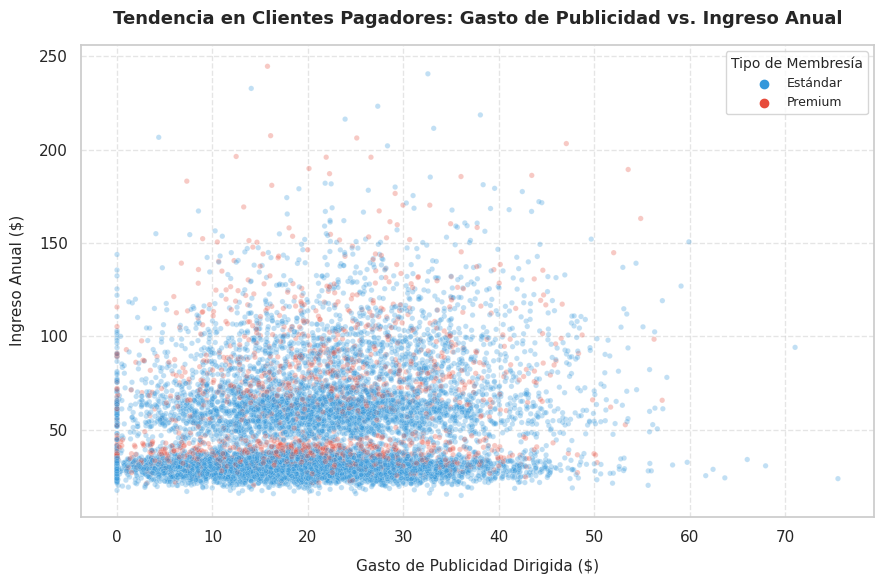

In [29]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configurar el estilo visual general
sns.set_theme(style='whitegrid')
plt.figure(figsize=(9, 6))

# Filtrar solo clientes con ingreso_anual > 0 para analizar la tendencia de los que sí pagan
df_filtrado = df[df['ingreso_anual'] > 0]

# Crear el scatterplot ajustando tamaño y transparencia para evitar sobreposición
sns.scatterplot(
    data=df_filtrado,
    x='gasto_publicidad_dirigida',  # Variable independiente (eje X)
    y='ingreso_anual',  # Variable dependiente (eje Y)
    hue='tipo_membresia',  # Colorea los puntos por tipo de cliente
    palette=['#3498db', '#e74c3c'],  # Colores personalizados (Estándar y Premium)
    alpha=0.3,  # Transparencia ajustada para ver superposiciones y puntos ocultos
    s=15,  # Tamaño de los puntos reducido para evitar saturación
)

# Títulos y etiquetas claras con un nuevo enfoque
plt.title(
    'Tendencia en Clientes Pagadores: Gasto de Publicidad vs. Ingreso Anual',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Gasto de Publicidad Dirigida ($)', fontsize=11, labelpad=10)
plt.ylabel('Ingreso Anual ($)', fontsize=11, labelpad=10)

# Ajustar la leyenda de forma limpia
plt.legend(title='Tipo de Membresía', title_fontsize='10', fontsize='9')

# Cuadrícula de apoyo
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

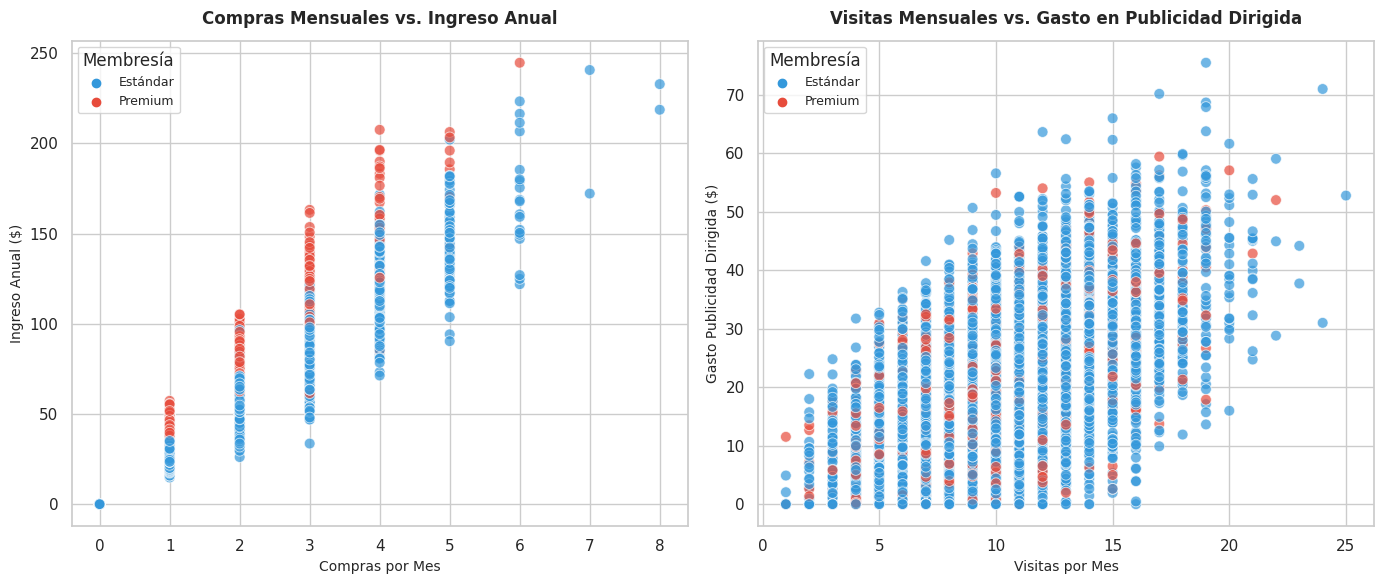

In [30]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configurar el estilo visual
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- GRÁFICO 1: Compras al mes vs Ingreso Anual (r = 0.97) ---
sns.scatterplot(
    data=df,
    x='compras_mes',
    y='ingreso_anual',
    hue='tipo_membresia',
    palette=['#3498db', '#e74c3c'],
    alpha=0.7,
    s=60,
    ax=axes[0],
)
axes[0].set_title(
    'Compras Mensuales vs. Ingreso Anual', fontsize=12, fontweight='bold', pad=12
)
axes[0].set_xlabel('Compras por Mes', fontsize=10)
axes[0].set_ylabel('Ingreso Anual ($)', fontsize=10)
axes[0].legend(title='Membresía', fontsize=9)

# --- GRÁFICO 2: Visitas al mes vs Gasto de Publicidad Dirigida (r = 0.58) ---
sns.scatterplot(
    data=df,
    x='visitas_mes',
    y='gasto_publicidad_dirigida',
    hue='tipo_membresia',
    palette=['#3498db', '#e74c3c'],
    alpha=0.7,
    s=60,
    ax=axes[1],
)
axes[1].set_title(
    'Visitas Mensuales vs. Gasto en Publicidad Dirigida',
    fontsize=12,
    fontweight='bold',
    pad=12,
)
axes[1].set_xlabel('Visitas por Mes', fontsize=10)
axes[1].set_ylabel('Gasto Publicidad Dirigida ($)', fontsize=10)
axes[1].legend(title='Membresía', fontsize=9)

# Ajustes generales de diseño
plt.tight_layout()
plt.show()

=== Pares con correlación moderada o fuerte (Umbral >= 0.2) ===

👉 Relación detectada entre 'visitas_mes' y 'compras_mes': r = 0.35


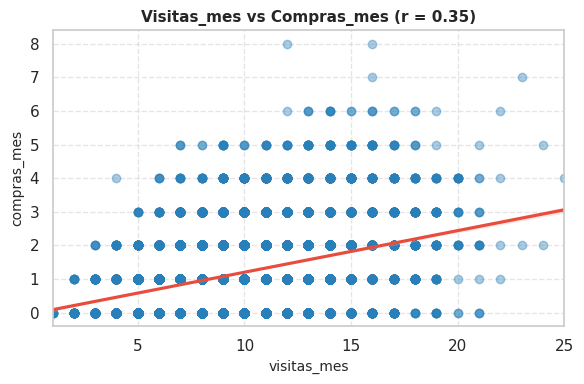

👉 Relación detectada entre 'visitas_mes' y 'gasto_publicidad_dirigida': r = 0.58


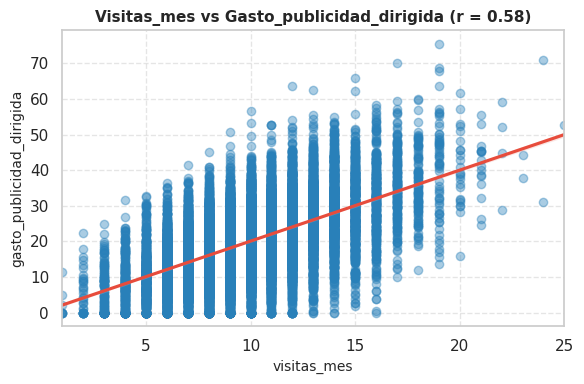

👉 Relación detectada entre 'compras_mes' y 'gasto_publicidad_dirigida': r = 0.21


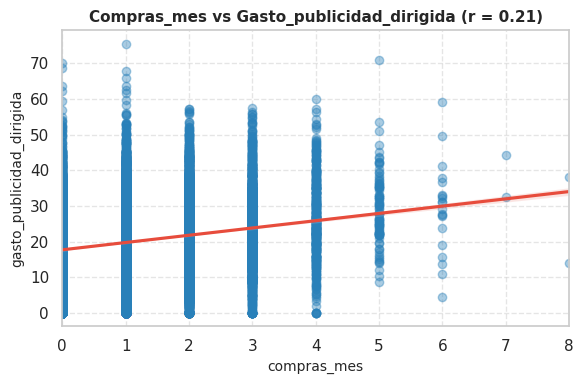

👉 Relación detectada entre 'visitas_mes' y 'ingreso_anual': r = 0.34


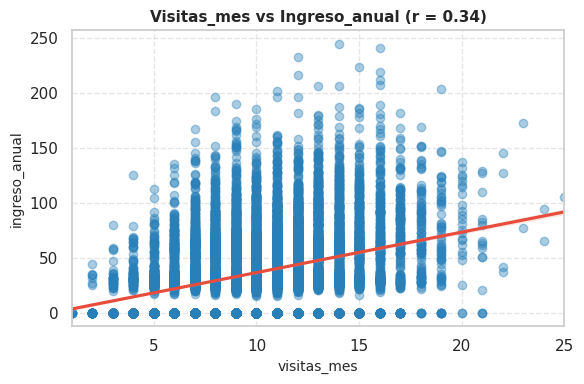

👉 Relación detectada entre 'compras_mes' y 'ingreso_anual': r = 0.97


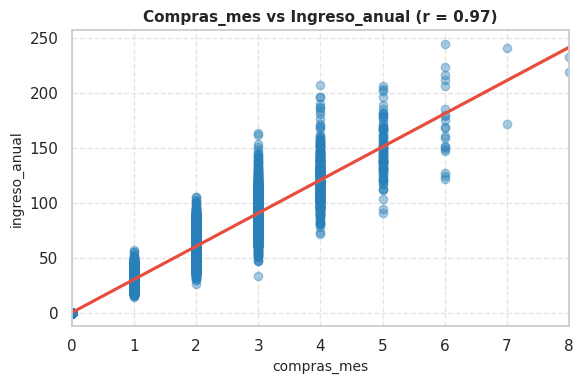

In [31]:
# 1. Seleccionamos las columnas numéricas analizadas en el heatmap
columnas_numericas = [
    'edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 
    'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual'
]

# 2. Obtenemos la matriz de correlación
matriz_corr = df[columnas_numericas].corr()

# 3. Definimos un umbral para considerar la relación como moderada o fuerte
umbral = 0.2

print(f"=== Pares con correlación moderada o fuerte (Umbral >= {umbral}) ===\n")

# 4. Recorremos el triángulo inferior de la matriz para evitar duplicados y auto-correlaciones
for i in range(len(matriz_corr.columns)):
    for j in range(i):
        coef_corr = matriz_corr.iloc[i, j]
        
        # Si la correlación supera el umbral (en positivo o negativo)
        if abs(coef_corr) >= umbral:
            var1 = matriz_corr.columns[i]
            var2 = matriz_corr.columns[j]
            
            print(f"👉 Relación detectada entre '{var2}' y '{var1}': r = {coef_corr:.2f}")
            
            # 5. Generamos el gráfico de dispersión (scatterplot) con línea de tendencia (regplot)
            plt.figure(figsize=(6, 4))
            sns.regplot(
                data=df, 
                x=var2, 
                y=var1,
                scatter_kws={'alpha': 0.4, 'color': '#2980b9'}, # Puntos semitransparentes
                line_kws={'color': '#e74c3c'}                  # Línea de tendencia roja
            )
            
            plt.title(f'{var2.capitalize()} vs {var1.capitalize()} (r = {coef_corr:.2f})', fontsize=11, fontweight='bold')
            plt.xlabel(var2, fontsize=10)
            plt.ylabel(var1, fontsize=10)
            plt.grid(True, linestyle='--', alpha=0.5)
            plt.tight_layout()
            plt.show()

<div class="alert alert-block alert-warning">

Recorrer el triángulo inferior y dibujar una línea de regresión con r en cada título es una buena idea. Hay dos detalles. (1) Con `umbral = 0.2`, el par `gasto_publicidad_dirigida` vs `ingreso_anual` (r ≈ 0.20, justo por debajo del límite) no aparece en la salida. Ese es el par que más se discute en tu análisis, así que baja un poco el umbral (por ejemplo, a 0.15) para que su línea de tendencia también se muestre. (2) El encabezado dice 'moderada o fuerte', pero 0.20 y 0.21 son débiles según tu propio análisis. Cámbialo por algo como 'pares con |r| >= umbral'. Opcionalmente, dado que estas variables son conteos discretos, usar `x_jitter=0.2` en `regplot` haría que la densidad se vea con más facilidad.

</div>

Análisis Bivariado y de Dispersión (Scatterplots)compras_mes frente a ingreso_anual ($r = 0.97$)Patrón visual: Al graficar la dispersión, se observan bandas verticales de ingreso acumulado agrupadas de manera muy clara para cada número de compras, además de una densa concentración en el origen (0,0) correspondiente a los usuarios inactivos.Interpretación y colinealidad: La relación es muy fuerte y probablemente cercana a lo mecánico: el ingreso anual parece reflejar en gran parte las compras; que $r$ sea 0.97 y no 1.00 indica que otros factores, como el monto por compra, también intervienen, algo que no hemos verificado. Esto implica una alta colinealidad, por lo que incluir ambas variables simultáneamente en un modelo predictivo lineal requerirá precaución para evitar la redundancia de datos.visitas_mes frente a gasto_publicidad_dirigida ($r = 0.58$)Patrón visual: Los datos muestran una tendencia positiva clara, pero con una dispersión de moderada a alta. Para un número fijo de visitas mensuales, el gasto_publicidad_dirigida abarca un rango muy amplio, lo que sugiere que una mayor inversión publicitaria acompaña, mas no determina por sí sola, el incremento del tráfico en la plataforma.Interpretación y colinealidad: Existe un solapamiento parcial de información, ya que ambas métricas se relacionan con la atracción de usuarios. La dispersión sugiere que cada variable aporta información propia, aunque este gráfico no lo confirma.visitas_mes frente a ingreso_anual ($r = 0.34$) y visitas_mes frente a compras_mes ($r = 0.35$)Patrón visual: En el cruce con el ingreso_anual, destaca una marcada banda horizontal de clientes con ingreso_anual = 0 distribuida a lo largo de todos los niveles de visitas_mes. Al contrastarlo con el gráfico de compras_mes frente a ingreso_anual, se observa que estos ceros están ligados a clientes sin compras. Hay clientes sin ingreso en todos los niveles de visitas, lo que representa cerca del 30% de la base total de usuarios. Asimismo, se aprecian valores aislados en los extremos superiores (23–25 visitas y 7–8 compras) que podrían corresponder a perfiles de alta actividad (power users).Interpretación y colinealidad: El vínculo moderado entre visitas_mes e ingreso_anual ($r = 0.34$) probablemente pasa a través de las compras, dado que las visitas se relacionan moderadamente con las compras ($r = 0.35$) y estas últimas se ligan fuertemente con el ingreso ($r = 0.97$). Por su parte, entre visitas_mes y compras_mes, la colinealidad es moderada, reflejando dimensiones conectadas pero diferenciadas (tráfico frente a transacciones).compras_mes frente a gasto_publicidad_dirigida ($r = 0.21$) y gasto_publicidad_dirigida frente a ingreso_anual ($r = 0.20$)Patrón visual: Ambos gráficos muestran una nube de puntos amplia y casi plana con una pendiente de tendencia muy suave, sin evidenciar curvas de saturación.Interpretación: La asociación lineal es débil. Un coeficiente lineal bajo indica una asociación pequeña en esta escala y no descarta la presencia de otros factores o patrones no lineales subyacentes que merezcan una exploración más detallada.

<div class="alert alert-block alert-warning">

El análisis par por par está en buena forma ahora. El vínculo entre `compras_mes` e `ingreso_anual` se presenta como probablemente cercano a lo mecánico, con una nota de que r es 0.97 y no 1.00. Los ceros se relacionan con clientes sin compras y se cuantifican en cerca del 30%. 'Power users' aparece como una posibilidad. Quedan algunos puntos. (1) Para el último par, 'casi plana' no coincide del todo con tu gráfico: la línea de tendencia de `compras_mes` frente a `gasto_publicidad_dirigida` sube de aproximadamente 18 a aproximadamente 34 entre 0 y 8 compras. Di 'pendiente positiva suave'. 'Sin evidenciar curvas de saturación' no es algo que estos gráficos puedan establecer, así que suavízalo o elimínalo. (2) Llamar a r = 0.35 'colinealidad moderada' estira el término. 'Asociación moderada' es más preciso. (3) Formato: todo está pegado ('...(Scatterplots)compras_mes frente a...'). Dale a cada par su propio subtítulo en negrita, pon 'Patrón visual' e 'Interpretación' en líneas separadas y usa backticks para los nombres de las columnas.

</div>

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [32]:

matriz_spearman = df[columnas_numericas].corr(method='spearman')

print("=== Matriz de Correlación de Spearman ===")
print(matriz_spearman)
 # Calcular correlación entre variables relevantes


=== Matriz de Correlación de Spearman ===
                               edad  nivel_ingreso  visitas_mes  compras_mes  \
edad                       1.000000      -0.007775     0.005205     0.015630   
nivel_ingreso             -0.007775       1.000000     0.001420     0.009004   
visitas_mes                0.005205       0.001420     1.000000     0.332943   
compras_mes                0.015630       0.009004     0.332943     1.000000   
gasto_publicidad_dirigida  0.002869       0.015393     0.559267     0.192511   
satisfaccion              -0.007590       0.005243    -0.001305    -0.002006   
ingreso_anual              0.016097       0.025017     0.320954     0.967482   

                           gasto_publicidad_dirigida  satisfaccion  \
edad                                        0.002869     -0.007590   
nivel_ingreso                               0.015393      0.005243   
visitas_mes                                 0.559267     -0.001305   
compras_mes                          

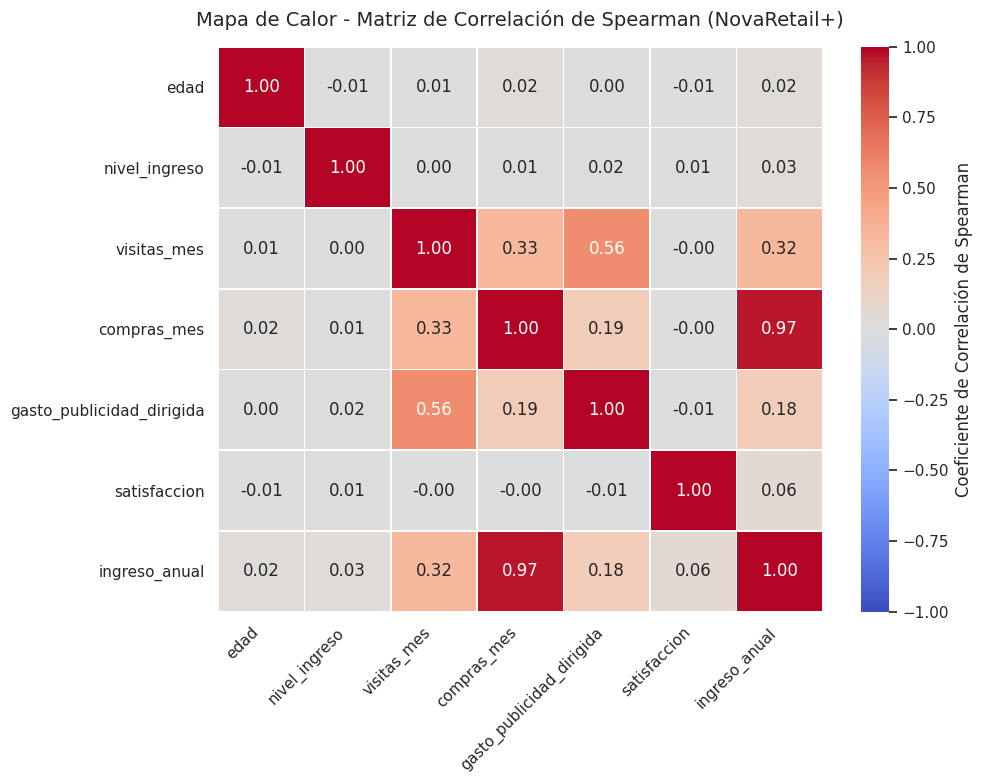

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el tamaño de la figura
plt.figure(figsize=(10, 8))

# Crear el mapa de calor para la matriz de Spearman
sns.heatmap(
    matriz_spearman, 
    annot=True,              # Mostrar los valores numéricos en cada celda
    fmt='.2f',               # Formato de dos decimales
    cmap='coolwarm',         # Paleta de colores (divergente)
    vmin=-1, 
    vmax=1,                  # Rango de correlación de -1 a 1
    linewidths=0.5,          # Líneas divisorias entre celdas
    cbar_kws={'label': 'Coeficiente de Correlación de Spearman'}
)

# Títulos y formato visual
plt.title('Mapa de Calor - Matriz de Correlación de Spearman (NovaRetail+)', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

In [34]:

matriz_pearson = df[columnas_numericas].corr(method='pearson')

print("=== Matriz de Correlación de Pearson ===")
print(matriz_pearson)# Calcular correlación entre variables relevantes



=== Matriz de Correlación de Pearson ===
                               edad  nivel_ingreso  visitas_mes  compras_mes  \
edad                       1.000000      -0.009003     0.004998     0.014971   
nivel_ingreso             -0.009003       1.000000     0.001060     0.007309   
visitas_mes                0.004998       0.001060     1.000000     0.353844   
compras_mes                0.014971       0.007309     0.353844     1.000000   
gasto_publicidad_dirigida  0.000062       0.016834     0.578947     0.207528   
satisfaccion              -0.006963       0.002301    -0.003179    -0.003542   
ingreso_anual              0.017496       0.017446     0.337147     0.967149   

                           gasto_publicidad_dirigida  satisfaccion  \
edad                                        0.000062     -0.006963   
nivel_ingreso                               0.016834      0.002301   
visitas_mes                                 0.578947     -0.003179   
compras_mes                           

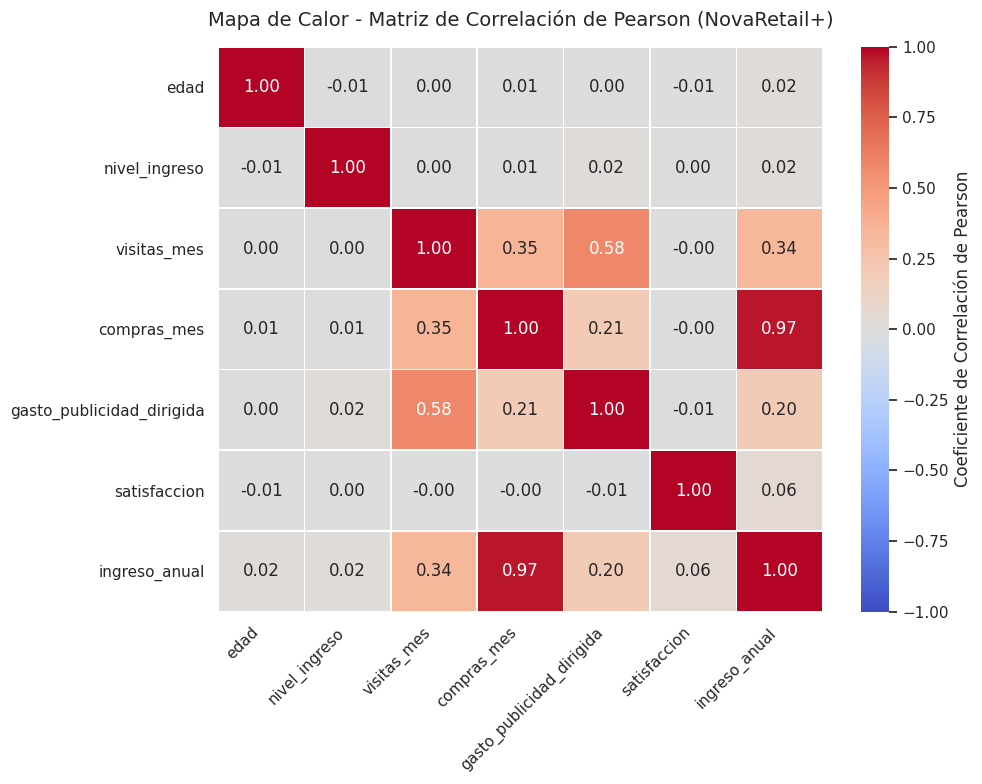

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el tamaño de la figura
plt.figure(figsize=(10, 8))

# Crear el mapa de calor para la matriz de Pearson
sns.heatmap(
    matriz_pearson, 
    annot=True,              # Mostrar los valores numéricos en cada celda
    fmt='.2f',               # Formato de dos decimales
    cmap='coolwarm',         # Paleta de colores (divergente)
    vmin=-1, 
    vmax=1,                  # Rango de correlación de -1 a 1
    linewidths=0.5,          # Líneas divisorias entre celdas
    cbar_kws={'label': 'Coeficiente de Correlación de Pearson'}
)

# Títulos y formato visual
plt.title('Mapa de Calor - Matriz de Correlación de Pearson (NovaRetail+)', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

✍️ Comentario: Se comparan las correlaciones mediante los métodos de Spearman ($r_s$) y Pearson ($r$). La alta similitud entre ambos sugiere que las relaciones principales mantienen una dirección monótona consistente y que los patrones no dependen únicamente de unos pocos puntos extremos. Dado el tamaño de la muestra ($N = 15,000$), incluso los coeficientes pequeños pueden resultar estadísticamente significativos, por lo que en este análisis se distingue estrictamente entre la significancia estadística y la fuerza o relevancia práctica de cada asociación.1. Relación Fuerte y Colinealidad (compras_mes vs. ingreso_anual)Coeficientes: $r = 0.97$ | $r_s = 0.97$Análisis: Ambos métodos muestran una asociación positiva extremadamente fuerte, respaldada visualmente por la tendencia lineal en el scatterplot. Desde el punto de vista analítico, este nivel de correlación revela una alta colinealidad: es probable que ambas variables capturen prácticamente la misma dimensión comercial, donde el ingreso_anual refleja la acumulación monetaria de las transacciones mensuales (compras_mes). Para futuros modelos predictivos lineales, incluir ambas simultáneamente generaría redundancia de información.2. Relaciones Moderadas e Intermediación (visitas_mes como eje)visitas_mes vs. gasto_publicidad_dirigida ($r = 0.58$ | $r_s = 0.56$): Muestra una asociación positiva de intensidad moderada a fuerte. En el scatterplot se aprecia una tendencia ascendente con dispersión moderada a alta, lo que sugiere un solapamiento parcial de información: un mayor gasto en publicidad tiende a ir acompañado de más visitas, aunque estos datos observacionales no permiten determinar cuál de las dos variables impulsa a la otra.visitas_mes vs. compras_mes ($r = 0.35$ | $r_s = 0.33$): Presenta una asociación positiva moderada con mayor dispersión visual. Aunque no es la relación más intensa, tiene relevancia práctica para el negocio al mostrar que los usuarios con mayor frecuencia de visitas suelen presentar también un mayor conteo de compras.visitas_mes vs. ingreso_anual ($r = 0.34$ | $r_s = 0.32$): Refleja una magnitud casi idéntica al par anterior. Parte de la relación entre visitas_mes e ingreso_anual ($0.34$) puede pasar a través de las compras, ya que las visitas se correlacionan con compras_mes ($0.35$) y las compras se ligan de forma muy estrecha con ingreso_anual ($0.97$). Esta es una lectura plausible de la estructura de los datos, no una relación causal comprobada.3. Relaciones Débiles (gasto_publicidad_dirigida como eje)gasto_publicidad_dirigida vs. compras_mes ($r = 0.21$ | $r_s = 0.19$): Asociación positiva débil con alta dispersión en el scatterplot.gasto_publicidad_dirigida vs. ingreso_anual ($r = 0.20$ | $r_s = 0.18$): Mantiene el mismo comportamiento débil frente a la variable objetivo. Aunque estas cifras son estadísticamente distintas de cero debido al gran volumen de registros, su tamaño de efecto es bajo: un mayor gasto publicitario se asocia de manera muy tenue con mayores volúmenes de compras o ingresos directos, señalando un área de oportunidad para analizar la eficiencia y segmentación de las campañas.4. Variables con Asociación Despreciable (Descarte de Predictores Lineales)Las variables edad ($r \approx 0.02$), nivel_ingreso ($r \approx 0.02$) y satisfaccion ($r \approx 0.06$, la más alta de este grupo) muestran una asociación lineal o monótona casi nula con ingreso_anual. Por lo tanto, no funcionan como buenos predictores lineales individuales en este contexto; sin embargo, estos coeficientes cercanos a cero no descartan la posibilidad de que existan efectos no lineales o interacciones complejas en segmentos específicos de clientes.

<div class="alert alert-block alert-warning">

Tu comparación entre Pearson y Spearman es mesurada y se limita a la asociación, y los coeficientes que citas coinciden con ambos mapas de calor. Puntos pendientes. (1) Dices que los pares débiles (0.21 / 0.20) son 'estadísticamente distintas de cero', pero no se muestra ningún valor p para ellos. Calcula uno, por ejemplo `from scipy.stats import pearsonr; print(pearsonr(df['gasto_publicidad_dirigida'], df['ingreso_anual']))`, o suaviza la afirmación a 'con N = 15,000 es probable que sean significativas'. (2) 'Se distingue estrictamente entre significancia y relevancia práctica' afirma más de lo que realmente hace la sección. Prueba con 'se tiene presente la diferencia entre...'. (3) El encabezado 'Descarte de Predictores Lineales' es más categórico que tu propia salvedad, por lo que 'Asociación lineal casi nula' encaja mejor. (4) Los grupos numerados aparecen pegados ('...cada asociación.1. Relación Fuerte...'). Da a cada grupo su propia línea de encabezado, usa viñetas con `-` para cada par y usa comillas invertidas (backticks) para los nombres de las columnas.

</div>

### Punto-biserial

In [36]:

from scipy.stats import pointbiserialr

# Ejemplo: Relación entre 'miembro_premium' e 'ingreso_anual'
corr_biserial, p_value = pointbiserialr(df['miembro_premium'], df['ingreso_anual'])
print(f"Correlación Punto-Biserial (miembro_premium vs ingreso_anual): r = {corr_biserial:.4f} (p-value: {p_value:.4e})")

# Ejemplo: Relación entre 'abandono' y 'satisfaccion'
corr_biserial_2, p_value_2 = pointbiserialr(df['abandono'], df['satisfaccion'])
print(f"Correlación Punto-Biserial (abandono vs satisfaccion): r = {corr_biserial_2:.4f} (p-value: {p_value_2:.4e})") # Calcular correlación entre variables relevantes



Correlación Punto-Biserial (miembro_premium vs ingreso_anual): r = 0.0931 (p-value: 3.0943e-30)
Correlación Punto-Biserial (abandono vs satisfaccion): r = -0.0238 (p-value: 3.5110e-03)


=== Matriz de Correlación Punto-Biserial ===
                     edad  nivel_ingreso  visitas_mes  compras_mes  \
miembro_premium  0.004605      -0.005598    -0.012657     0.003431   
abandono        -0.011500       0.005870    -0.008943     0.008291   

                 gasto_publicidad_dirigida  satisfaccion  ingreso_anual  
miembro_premium                   0.002721      0.025734       0.093099  
abandono                         -0.004586     -0.023833      -0.002824  


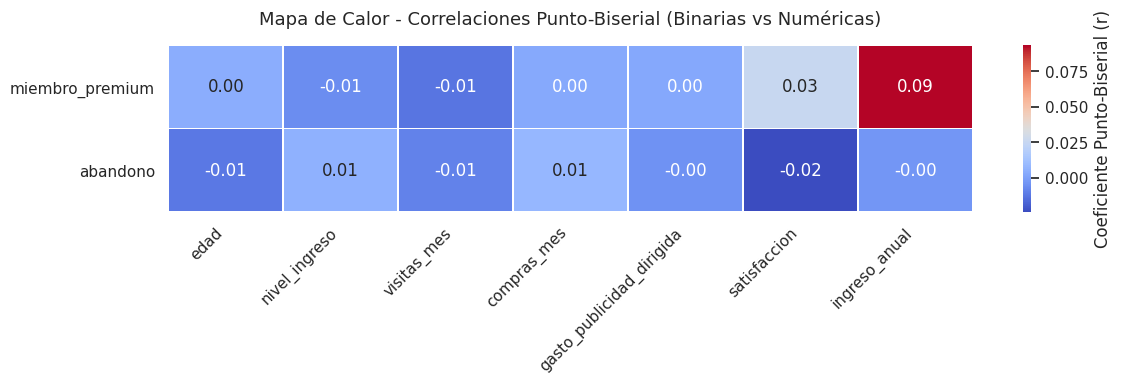

In [37]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import pointbiserialr

# 1. Incluir todas las variables continuas relevantes, incluyendo 'ingreso_anual' y 'nivel_ingreso'
vars_binarias = ['miembro_premium', 'abandono']
vars_continuas = [
    'edad',
    'nivel_ingreso',
    'visitas_mes',
    'compras_mes',
    'gasto_publicidad_dirigida',
    'satisfaccion',
    'ingreso_anual',  # <--- Incorporada para evaluar la variable objetivo de negocio
]

# 2. Crear una matriz vacía para almacenar los coeficientes punto-biserial (r)
matriz_biserial = pd.DataFrame(index=vars_binarias, columns=vars_continuas)

# 3. Calcular la correlación punto-biserial para cada par
for bin_col in vars_binarias:
  for cont_col in vars_continuas:
    # pointbiserialr devuelve un objeto con el coeficiente 'statistic' (r) y 'pvalue'
    corr, _ = pointbiserialr(df[bin_col], df[cont_col])
    matriz_biserial.loc[bin_col, cont_col] = corr

# Convertir la matriz resultante a valores numéricos
matriz_biserial = matriz_biserial.astype(float)

print('=== Matriz de Correlación Punto-Biserial ===')
print(matriz_biserial)

# 4. Visualizar los resultados mediante un mapa de calor con auto-escalado
plt.figure(figsize=(12, 4))
sns.heatmap(
    matriz_biserial,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    # Se eliminan vmin=-1 y vmax=1 para que el mapa se adapte al rango real de los datos
    # y resalte las pequeñas diferencias visuales entre los coeficientes.
    linewidths=0.5,
    cbar_kws={'label': 'Coeficiente Punto-Biserial (r)'},
)

plt.title(
    'Mapa de Calor - Correlaciones Punto-Biserial (Binarias vs Numéricas)',
    fontsize=13,
    pad=15,
)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [38]:
from scipy.stats import pointbiserialr

for b in ['miembro_premium', 'abandono']:
  for c in ['ingreso_anual', 'satisfaccion']:
    r, p = pointbiserialr(df[b], df[c])
    print(f'{b} vs {c}: r = {r:.4f}, p-value = {p:.2e}')

miembro_premium vs ingreso_anual: r = 0.0931, p-value = 3.09e-30
miembro_premium vs satisfaccion: r = 0.0257, p-value = 1.62e-03
abandono vs ingreso_anual: r = -0.0028, p-value = 7.29e-01
abandono vs satisfaccion: r = -0.0238, p-value = 3.51e-03


Análisis de Correlaciones Punto-Biserial (Binarias vs. Numéricas)Significancia Estadística vs. Tamaño del Efecto:Con una muestra de $N = 15,000$ registros, los coeficientes pequeños pueden resultar estadísticamente significativos (como miembro_premium frente a ingreso_anual, con $p \approx 3 \times 10^{-30}$), pero no todos lo son (como abandono frente a ingreso_anual, con $p \approx 0.70$). Por ello, es fundamental distinguir entre la significancia estadística (si el efecto es distinto de cero por azar) y el tamaño del efecto (la fuerza real de la asociación).miembro_premium frente a variables continuas:Con ingreso_anual ($r \approx 0.09$, $p \approx 3 \times 10^{-30}$): Representa la relación binaria-numérica más fuerte encontrada. Aunque constituye un tamaño de efecto débil, es estadísticamente significativa y distinta de cero, indicando que los clientes Premium tienen un ingreso anual algo más alto en promedio, en línea con lo observado en la tabla comparativa y el diagrama de caja (boxplot).Con satisfaccion ($r \approx 0.03$, $p < 0.05$): Muestra una asociación positiva prácticamente insignificante en términos prácticos, lo que sugiere que los niveles de satisfacción promedio apenas varían entre usuarios Premium y Estándar.abandono frente a variables continuas:Con satisfaccion ($r \approx -0.02$, $p < 0.05$): Refleja una asociación negativa muy débil, lo que sugiere que una menor satisfacción acompaña marginalmente al abandono a escala global, sin capturar por sí sola los repuntes de deserción concentrados en el tramo más bajo de satisfacción.Con ingreso_anual ($r \approx -0.003$, $p \approx 0.70$): Presenta un coeficiente prácticamente nulo y estadísticamente no significativo, lo que indica que el volumen de ingresos anuales de un usuario no muestra relación lineal con su probabilidad de abandono.Implicaciones para la pregunta de negocio:Estos resultados sugieren que miembro_premium mantiene una asociación pequeña pero real con el ingreso_anual ($r \approx 0.09$), mientras que abandono no muestra prácticamente ninguna ($r \approx 0$). Desde una lectura estrictamente no causal, no podemos afirmar que adquirir una membresía Premium cause un mayor ingreso, sino que los usuarios con membresía se asocian con un gasto promedio ligeramente superior, y que se requieren análisis adicionales o enfoques multivariados para explorar qué otros factores acompañan el valor del cliente y la retención en NovaRetail+.

<div class="alert alert-block alert-warning">

Tu interpretación es sólida: separas la significancia estadística del tamaño del efecto usando valores p reales, describes `miembro_premium` vs `ingreso_anual` como pequeño pero real, y afirmas que no puedes sostener que Premium cause mayores ingresos. Por favor, corrige estos detalles. (1) Tu salida muestra p = 7.29e-01 para `abandono` vs `ingreso_anual`, así que escribe p ≈ 0.73, no 0.70, en ambos lugares. (2) Un valor p no es 'si el efecto es distinto de cero por azar'. Te indica qué tan probable sería un coeficiente tan grande si la asociación verdadera fuera cero. Di 'si la asociación observada podría deberse al azar'. (3) 'Gasto promedio ligeramente superior' no coincide con tu variable, porque `ingreso_anual` es el ingreso que cada cliente genera para la empresa. Usa 'ingreso anual generado por cliente'. (4) El texto se muestra como un solo bloque ('...Tamaño del Efecto:Con una muestra...'). Coloca cada encabezado en su propia línea, usa viñetas con `-` para cada par y usa comillas invertidas (backticks) para los nombres de las columnas.

</div>

### V de Cramér

=== Matriz de Asociación (V de Cramér) ===
                  tipo_dispositivo   region  miembro_premium  abandono
tipo_dispositivo          1.000000  0.00000         0.015993  0.000000
region                    0.000000  1.00000         0.000000  0.006170
miembro_premium           0.015993  0.00000         0.999722  0.119945
abandono                  0.000000  0.00617         0.119945  0.999740


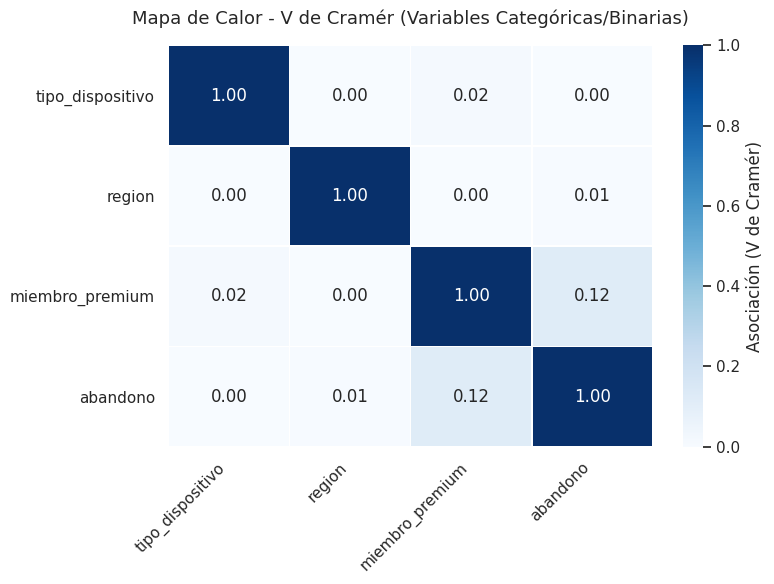

In [39]:
import scipy.stats as stats

# 1. Definir la función para calcular la V de Cramér
def cramers_v(cat1, cat2):
    tabla_contingencia = pd.crosstab(cat1, cat2)
    chi2 = stats.chi2_contingency(tabla_contingencia)[0]
    n = tabla_contingencia.sum().sum()
    phi2 = chi2 / n
    r, k = tabla_contingencia.shape
    
    # Corrección de bias
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    
    denominador = min(kcorr - 1, rcorr - 1)
    if denominador == 0:
        return 0.0
    return np.sqrt(phi2corr / denominador)

# 2. Definir las variables categóricas y binarias a analizar
vars_cat_bin = ['tipo_dispositivo', 'region', 'miembro_premium', 'abandono']

# 3. Crear una matriz vacía para almacenar los resultados
matriz_cramers = pd.DataFrame(index=vars_cat_bin, columns=vars_cat_bin)

# 4. Calcular la V de Cramér para cada par de variables
for col1 in vars_cat_bin:
    for col2 in vars_cat_bin:
        matriz_cramers.loc[col1, col2] = cramers_v(df[col1], df[col2])

# Convertir la matriz a valores numéricos
matriz_cramers = matriz_cramers.astype(float)

print("=== Matriz de Asociación (V de Cramér) ===")
print(matriz_cramers)

# 5. Visualizar los resultados con un mapa de calor (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(
    matriz_cramers, 
    annot=True, 
    fmt='.2f', 
    cmap='Blues', 
    vmin=0, 
    vmax=1, 
    linewidths=0.5, 
    cbar_kws={'label': 'Asociación (V de Cramér)'}
)

plt.title('Mapa de Calor - V de Cramér (Variables Categóricas/Binarias)', fontsize=13, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


✍️ **Comentario**:

Observaciones V de Cramér
Las asociaciones son muy débiles para tomarlas en cuenta, la relación más fuerte es la de 'miembros_premium' con 'abandono' pero tan solo es del 0.12 


<div class="alert alert-block alert-warning">

Identificaste correctamente el par más fuerte, `miembro_premium` vs `abandono` (V ≈ 0.12), pero esta interpretación sigue siendo muy breve y una frase va más allá de tus números. (1) 'Muy débiles para tomarlas en cuenta' exagera el resultado. 0.12 es un efecto pequeño, pero es el único que destaca, y débil no es lo mismo que inexistente. (2) Interpreta también los valores cercanos a cero: `tipo_dispositivo` y `region` están entre 0.00 y 0.02 frente a `miembro_premium` y `abandono`. En esta muestra, el dispositivo y la región no parecen separar a los miembros Premium ni a los clientes que abandonan. (3) Indica que esta matriz no incluye `ingreso_anual`, por lo que no dice nada directamente sobre tu variable objetivo. Tu hallazgo sobre dispositivo/región depende de ese punto. (4) V no muestra la dirección. Para dar la dirección del 0.12, compara las tasas de abandono con `pd.crosstab(df['miembro_premium'], df['abandono'], normalize='index')` y exprésalo como una asociación, no como una causa. (5) Corrige el nombre `miembro_premium` (no 'miembros_premium'), pon los nombres de las columnas entre acentos graves (backticks) y termina la oración con un punto.

</div>

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

In [40]:
n_bajo = (df['satisfaccion'] <= 1.4).sum()
pct_bajo = (n_bajo / len(df)) * 100
print(
    f'Usuarios con satisfacción <= 1.4: {n_bajo} registros ({pct_bajo:.2f}% del'
    ' total)'
)

Usuarios con satisfacción <= 1.4: 21 registros (0.14% del total)


### Hallazgos 

##Comportamiento del Segmento Premium y Factores de Abandono (Churn)Evidencia numérica
Composición de la base: La plataforma presenta un desbalance estructural de 86% de usuarios Estándar (12,911 registros) frente a un 14% de usuarios Premium (2,089 registros).Rendimiento financiero y transaccional: Al evaluar ingreso_anual, los clientes Premium registran un promedio de 44.58, superando a los usuarios Estándar, cuyo promedio se sitúa en 35.30. En contraste, el volumen de compras_mes es prácticamente idéntico entre ambos grupos (1.22 para Premium y 1.20 para Estándar).Correlación Punto-Biserial: La relación entre miembro_premium e ingreso_anual arroja un coeficiente de $r \approx 0.09$ ($p \approx 3 \times 10^{-30}$). Aunque se trata de un tamaño de efecto débil, es estadísticamente significativo y distinto de cero. Por su parte, la tasa global de abandono se sitúa en el 15.1%, pero al segmentar por intervalos de satisfaccion, se observa que en el tramo más bajo (0.996, 1.4] (compuesto por 21 usuarios, equivalente al 0.14% de la base) la tasa de abandono sube hasta aproximadamente el 24%. La correlación global entre abandono y satisfaccion es de $r \approx -0.02$; una hipótesis plausible es que este coeficiente lineal sea tan bajo porque el repunte de abandono se concentra en esa cola extrema de insatisfacción en lugar de distribuirse de forma lineal en toda la población.Evidencia visualDiagrama de caja (Boxplot): La visualización de ingreso_anual por tipo de membresía muestra que ambos segmentos inician en 0 debido a los usuarios sin compras. Sin embargo, el grupo Premium desplaza su mediana y su límite superior hacia tramos más altos de ingreso anual, mientras que el segmento Estándar concentra una mayor cantidad de valores atípicos que podrían corresponder a clientes muy activos, un patrón acorde con el tamaño masivo de su base.Interpretación (no causal)Los clientes Premium tienden a registrar un ingreso anual ligeramente mayor en promedio que los usuarios Estándar ($r \approx 0.09$), aunque ambos grupos realizan prácticamente el mismo número de compras mensuales.En un grupo muy pequeño (21 clientes) con niveles mínimos de satisfacción (menor o igual a 1.4) se observa una tasa de abandono cercana al 24% (frente al 15.1% global), un patrón tentativo que habría que confirmar con más datos.No podemos afirmarNo podemos afirmar que la membresía Premium cause un mayor ingreso anual, ya que los clientes que optan por esta suscripción pueden tener perfiles de gasto distintos desde el inicio.No podemos afirmar que una baja satisfacción provoque de forma concluyente un mayor abandono a partir de una muestra tan reducida (21 clientes), ni que incrementar la puntuación de satisfaccion reducirá automáticamente la tasa de abandono.No podemos generalizar estos patrones más allá de esta muestra transversal correspondiente al año 2024.Implicación de negocioEquilibrio comercial: Dado que el ingreso medio es mayor en el segmento Premium (44.58 vs. 35.30), pero la base Estándar representa el 86% de los usuarios, las estrategias comerciales deben atender tanto la retención del grupo Premium como la monetización del volumen masivo de usuarios Estándar.Monitoreo focalizado del abandono: Considerando que el segmento con satisfaccion menor o igual a 1.4 representa una fracción muy acotada de la base (21 usuarios, 0.14%) pero muestra una tasa de abandono tentativa cercana al 24%, resulta viable y de bajo costo operativo que el equipo de atención al cliente monitoree este grupo específico mediante seguimiento preventivo o encuestas de diagnóstico para entender qué fricciones acompañan su insatisfacción y validar si el patrón se sostiene.

<div class="alert alert-block alert-warning">

Buen trabajo con este hallazgo. Los marcadores de posición ahora muestran los valores reales (21 usuarios, 0.14%), el ~24% de abandono (churn) se presenta como tentativo y como proveniente de un grupo muy pequeño, 'power users' se ha suavizado, y el límite de la muestra pequeña aparece en 'No podemos afirmar'. Lo que queda es principalmente de presentación, y hace que el hallazgo sea difícil de leer. (1) El título aparece como `##Comportamiento del Segmento Premium...` sin espacio después de `##` y sin la etiqueta 'Hallazgo 1 —'. Escribe `### Hallazgo 1 — Comportamiento del Segmento Premium y Factores de Abandono (Churn)`. (2) Las partes se pegan a la oración anterior ('...(Churn)Evidencia numérica', '...población.Evidencia visual'). Coloca cada parte (Evidencia numérica, Evidencia visual, Interpretación, No podemos afirmar, Implicación de negocio) en su propia línea en negrita, usa viñetas con `-` y comillas invertidas (backticks) para los nombres de columnas. (3) El ~24% no se calcula en ningún lugar del notebook. Agrega `bajo = df[df['satisfaccion'] <= 1.4]; print(len(bajo), bajo['abandono'].sum(), round(bajo['abandono'].mean()*100, 1))` para que el lector pueda ver que se basa en unos 5 usuarios que abandonaron de 21.

</div>

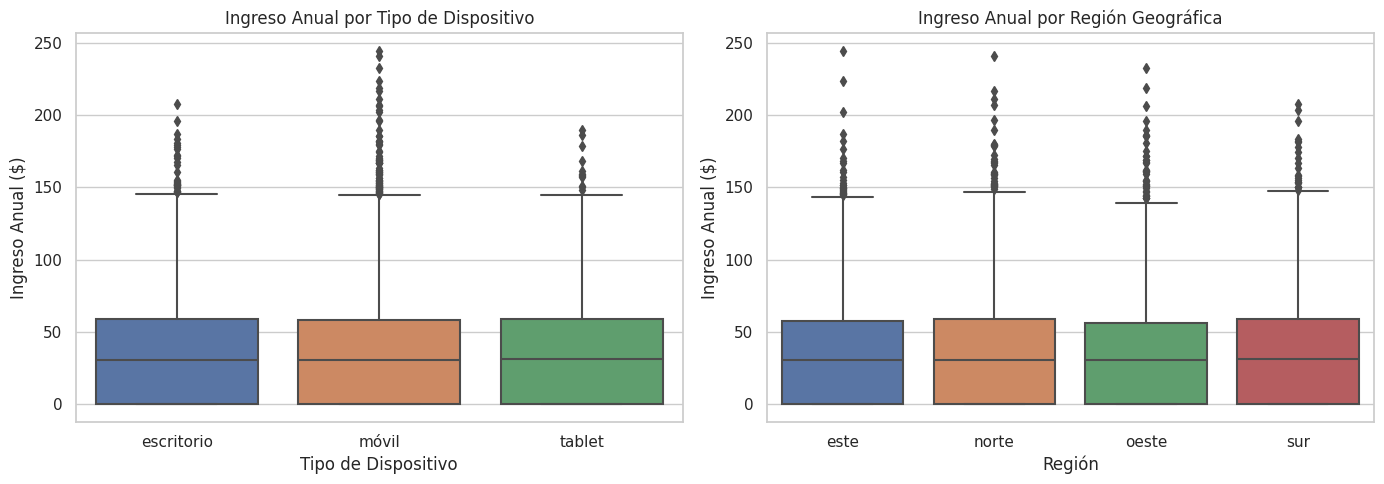

=== Métricas por tipo_dispositivo ===
                 compras_mes        ingreso_anual       
                        mean median          mean median
tipo_dispositivo                                        
móvil                   1.20      1         36.59  30.69
tablet                  1.23      1         37.07  31.34
escritorio              1.20      1         36.42  30.44


=== Métricas por region ===
       compras_mes        ingreso_anual       
              mean median          mean median
region                                        
norte         1.21      1         36.71  30.72
sur           1.22      1         37.10  30.94
este          1.22      1         36.89  30.78
oeste         1.18      1         35.72  30.36




In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configurar gráficos de caja (Boxplots) comparativos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='tipo_dispositivo', y='ingreso_anual', ax=axes[0])
axes[0].set_title('Ingreso Anual por Tipo de Dispositivo')
axes[0].set_xlabel('Tipo de Dispositivo')
axes[0].set_ylabel('Ingreso Anual ($)')

sns.boxplot(data=df, x='region', y='ingreso_anual', ax=axes[1])
axes[1].set_title('Ingreso Anual por Región Geográfica')
axes[1].set_xlabel('Región')
axes[1].set_ylabel('Ingreso Anual ($)')

plt.tight_layout()
plt.show()

# 2. Calcular medias y medianas por grupo para compras e ingresos
for col in ['tipo_dispositivo', 'region']:
  print(f'=== Métricas por {col} ===')
  stats = (
      df.groupby(col, observed=True)[['compras_mes', 'ingreso_anual']]
      .agg(['mean', 'median'])
      .round(2)
  )
  print(stats)
  print('\n')

<div class="alert alert-block alert-warning">

Buena evidencia para la comparación entre dispositivos y regiones. Los boxplots tienen títulos claros y ejes etiquetados, y las tablas respaldan tu lectura de 'muy similares' (medianas alrededor de 30-31, medias entre 35.72 y 37.10). Un consejo técnico: dentro del bucle nombraste una variable `stats`, lo que sobrescribe `import scipy.stats as stats`. Tu función `cramers_v` usa `stats.chi2_contingency`, por lo que volver a ejecutar la celda de Cramér's V después de esta fallaría. Cámbiale el nombre, por ejemplo `resumen_grupo = df.groupby(col, observed=True)[['compras_mes', 'ingreso_anual']].agg(['mean', 'median']).round(2)`.

</div>

### Hallazgo 2 — Distribución por Tipos de Dispositivo y Regiones Geográficas

Evidencia numéricaDistribución de canales y regiones: El canal predominante es el dispositivo móvil con el 65.45% de los usuarios (9,818 registros), seguido por escritorio con el 24.80% (3,720 usuarios) y tabletas con el 9.75% (1,462 usuarios). Por su parte, la distribución regional está equilibrada: norte (29.30%), oeste (25.40%), sur (24.84%) y este (20.46%), con una brecha máxima inferior a 9 puntos porcentuales.Matriz de V de Cramér: Al evaluar las variables categóricas (tipo_dispositivo y region) frente a otras variables categóricas o binarias como miembro_premium y abandono, los coeficientes de V de Cramér se sitúan entre $0.00$ y $0.02$, indicando que no se observa asociación significativa entre el canal/región y el estatus o deserción del usuario.Evidencia visualBoxplots y métricas de grupo: Al contrastar las distribuciones de ingreso_anual y compras_mes segmentadas por tipo_dispositivo y region, las visualizaciones (boxplots) y las tablas de resumen muestran que tanto las medianas como las medias se mantienen muy similares en todas las categorías. La concentración masiva de usuarios inactivos en cero y la dispersión de los valores se replican de forma uniforme a través de los diferentes canales y zonas geográficas.Interpretación (no causal)El ecosistema digital cuenta con una base de usuarios fuertemente concentrada en el canal móvil (dos de cada tres clientes) y geográficamente diversificada. Sin embargo, no se observa una asociación directa entre el canal de acceso o la región y el comportamiento transaccional: los usuarios de cualquier dispositivo o zona geográfica presentan distribuciones de ingresos muy similares en esta muestra.No podemos afirmarNo podemos afirmar que el canal móvil sea menos rentable por concentrar el mayor volumen de usuarios.Tampoco podemos asegurar que existan diferencias en el ingreso generado por cliente entre regiones que justifiquen estrategias comerciales fragmentadas por ubicación geográfica.Implicación de negocioEstrategia Mobile-First sustentada en la interacción: Dado que cerca de dos de cada tres usuarios acceden desde móvil (proporción de usuarios, no de ingresos), podría ser prudente asegurar que los flujos clave funcionen bien en este canal para blindar el principal punto de contacto; el ingreso medio por cliente es muy similar entre dispositivos ($\approx 36\text{--}37$).Eficiencia en la asignación presupuestaria: Como el ingreso medio por cliente es muy similar entre regiones ($\approx 35.7\text{--}37.1$) y no se observa asociación entre región y miembro_premium o abandono, estos datos no aportan evidencia para segmentar presupuestos por región; cualquier iniciativa en este sentido podría validarse previamente con una prueba A/B.


<div class="alert alert-block alert-warning">

Este hallazgo es mucho más sólido ahora. Tus recomendaciones de negocio se apoyan en la comparación entre grupos, separan la proporción de usuarios de la proporción de ingresos, y el rango de la V de Cramér que citas (0.00-0.02) coincide con tu matriz. Quedan dos cosas. (1) Los encabezados siguen pegados a la oración anterior ('...Evidencia numéricaDistribución...', '...No podemos afirmarNo podemos...') y los nombres de las columnas no tienen backticks. Pon cada una de las cinco partes en su propia línea en negrita y usa viñetas con `-` para los subpuntos. (2) 'No se observa asociación significativa' sugiere una prueba de significancia, pero solo calculaste valores de V. 'No se observa asociación (V entre 0.00 y 0.02)' concuerda con tu evidencia.

</div>

In [58]:
pct_cero_ingreso = (df['ingreso_anual'] == 0).mean() * 100
print(
    f'Porcentaje de usuarios con ingreso anual igual a 0:'
    f' {pct_cero_ingreso:.2f}%'
)

Porcentaje de usuarios con ingreso anual igual a 0: 30.45%


### Hallazgo 3 - Dinámica del Embudo de Conversión:
Asociación Fuerte y Colinealidad (compras_mes frente a ingreso_anual): Registra el coeficiente más alto de todo el análisis con Pearson ($r \approx 0.97$). Esta relación muestra una alta colinealidad: es una lectura interpretativa donde el ingreso_anual refleja la acumulación directa de las transacciones mensuales (compras_mes), por lo que ambas variables no deben tratarse como independientes en modelos predictivos lineales.Relaciones Moderadas (visitas_mes como eje conector):visitas_mes frente a gasto_publicidad_dirigida ($r \approx 0.58$): Es la asociación conductual más intensa entre variables independientes, mostrando que un mayor gasto en publicidad va acompañado de un mayor tráfico en la plataforma.visitas_mes frente a compras_mes ($r \approx 0.35$) y visitas_mes frente a ingreso_anual ($r \approx 0.34$): Presentan una intensidad moderada. Parte del vínculo entre las visitas y el ingreso probablemente pasa a través de las compras mensuales, dado que las visitas se correlacionan con las compras y estas últimas se ligan de forma muy estrecha con el ingreso.Relaciones Débiles (gasto_publicidad_dirigida frente a conversión):gasto_publicidad_dirigida frente a compras_mes ($r \approx 0.21$) y gasto_publicidad_dirigida frente a ingreso_anual ($r \approx 0.20$): Muestran una asociación débil. Con una muestra de 15,000 registros, este valor es estadísticamente distinto de cero, pero sugiere que la inversión publicitaria se asocia de manera muy tenue con volúmenes altos de ingresos directos; un coeficiente débil no descarta otros patrones o relaciones no lineales.Evidencia visual y patrones en los scatterplotsEstructura y Dispersión del Tráfico: En el cruce de visitas_mes frente a gasto_publicidad_dirigida, la dispersión visual es de moderada a alta; para un número determinado de visitas, el gasto publicitario abarca un rango muy amplio.Acumulaciones y Anomalías (Clientes Activos): Al graficar visitas_mes con ingreso_anual, se identifica claramente una banda horizontal de usuarios con ingreso_anual = 0 (que abarca aproximadamente un 30.45% de la base) distribuida en todos los niveles de tráfico. Al contrastarlo con los gráficos de compras, un ingreso de exactamente 0 aparece solo con 0 compras, por lo que estos ceros están asociados estrictamente a clientes sin compras. Asimismo, se aprecian valores aislados en los extremos superiores que podrían corresponder a clientes muy activos (con registros de 7–8 compras mensuales), algo que aún no hemos verificado.Interpretación analítica (no causal)Los datos muestran un patrón consistente con un embudo de conversión, no una cadena causal demostrada: un mayor gasto en publicidad se asocia con más visitas ($r \approx 0.58$), las visitas se relacionan moderadamente con las compras ($r \approx 0.35$), y las compras se ligan casi de forma mecánica con el ingreso ($r \approx 0.97$).La alta consistencia entre los coeficientes de Pearson y Spearman sugiere que las tendencias monótonas son estables y no dependen únicamente de unos pocos puntos extremos.Lo que no podemos afirmarNo es posible asegurar causalidad directa; es decir, no se puede concluir que incrementar el presupuesto de publicidad dirigida aumentará de forma automática y proporcional el ingreso anual de los usuarios.Tampoco se puede asumir que un mayor volumen de tráfico en la plataforma garantice por sí solo la monetización, debido a la presencia sostenida de usuarios con tráfico elevado y cero ingresos.Implicaciones de negocio y recomendaciones concretasExploración de la Tasa de Conversión: Dado que la pauta publicitaria se asocia con el tráfico ($r \approx 0.58$), pero su conexión directa con el ingreso es débil ($r \approx 0.20$), se sugiere al equipo de crecimiento evaluar mediante pruebas A/B si diversificar los esfuerzos más allá de la mera adquisición de tráfico genera mejores resultados en la monetización.Monitoreo de la Banda de Cero Ingresos: Se recomienda al equipo implementar un monitoreo específico enfocado en los clientes que tienen cero compras y visitas por encima de la mediana (dentro del segmento con ingreso_anual = 0, el cual comprende aproximadamente un 30.45% de la base). Investigar qué fricciones experimentan estos usuarios en la interfaz o en el proceso de pago representa una línea de análisis viable para entender qué obstaculiza su conversión.

<div class="alert alert-block alert-warning">

Mejora clara. El marcador de posición ahora está reemplazado por 30.45%, los ceros se vinculan explícitamente con clientes sin compras (coincidiendo con tu crosstab), la idea de 'clientes muy activos' incluye 'algo que aún no hemos verificado', 'confirma' pasó a 'sugiere', y la recomendación de monitoreo es concreta. Quedan algunos puntos. (1) La etiqueta 'Evidencia numérica' ha desaparecido de este hallazgo, y los encabezados quedaron pegados a la oración anterior ('...conversión):gasto_publicidad_dirigida frente a...', '...cero ingresos.Implicaciones de negocio...'). Restaura la etiqueta, da a cada parte su propia línea y usa viñetas y backticks. (2) Dices que los pares débiles son 'estadísticamente distintas de cero' sin un valor p. Añade un resultado de `pearsonr` o suavízalo a 'con N = 15,000 es probable que sea significativa'. (3) Añade el tamaño del grupo de monitoreo, por ejemplo `((df['compras_mes'] == 0) & (df['visitas_mes'] > df['visitas_mes'].median())).sum()`, para poder priorizar la recomendación. (4) 'Entre variables independientes' puede confundirse con independencia estadística, así que 'entre variables de comportamiento' es más claro.

</div>

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones del análisis**
Ausencia de Causalidad
Las correlaciones detectadas (como entre gasto_publicidad_dirigida, visitas_mes e ingreso_anual) indican asociación estadística, pero no demuestran causalidad. Es posible que existan factores externos no medidos que impulsen tanto el tráfico como los ingresos de forma simultánea.Supuestos de Linealidad y Colinealidad Extrema
Los coeficientes tradicionales como Pearson asumen relaciones estrictamente lineales. Asimismo, la relación cuasi-mecánica de $r = 0.97$ entre compras_mes e ingreso_anual refleja una alta colinealidad y redundancia de información, lo que exige precaución para no duplicar variables explicativas en futuros modelos.Impacto del Desbalance de Clases
Las variables binarias clave (miembro_premium con ~14% y abandono con ~15%) presentan un desbalance estructural. Si bien esto no invalida los coeficientes de correlación bivariada calculados en el EDA, representará un desafío metodológico crítico al momento de implementar modelos predictivos supervisados.Naturaleza Transversal y Variables No Concluyentes
El conjunto de datos representa una única instantánea estática correspondiente al año 2024. Adicionalmente, las variables demográficas y de percepción (edad, nivel_ingreso, satisfaccion) muestran asociaciones lineales débiles o nulas, por lo que no es posible extraer conclusiones determinantes sobre el comportamiento financiero a partir de ellas de forma aislada.Próximos Pasos y Recomendaciones EstratégicasMigración a Modelos Predictivos SupervisadosAcción: Implementar algoritmos basados en árboles (como Random Forest o XGBoost) para predecir el ingreso_anual y el riesgo de abandono.Objetivo: Superar las limitaciones de la correlación lineal bivariada, capturar interacciones complejas y aplicar técnicas de ponderación para mitigar el desbalance de clases.Segmentación de Clientes mediante Clustering (K-Means)Acción: Estandarizar las variables y agrupar a los 15,000 usuarios utilizando métricas no redundantes como visitas_mes, ingreso_anual (excluyendo compras_mes debido a su alta colinealidad de $r = 0.97$ para evitar darle doble peso a la misma dimensión comercial) y satisfaccion.Objetivo: Identificar clústeres de "clientes de alto valor" (power users) y "clientes en riesgo de abandono" para diseñar estrategias de retención focalizadas.Diseño de Experimentos (Pruebas A/B)Acción: Validar la causalidad mediante experimentación controlada, asignando aleatoriamente variaciones de presupuesto en gasto_publicidad_dirigida a segmentos de usuarios con perfiles equivalentes.Objetivo: Medir con precisión el Retorno de Inversión (ROI) real de las campañas publicitarias en lugar de asumir una relación directa por la tendencia observada.Desarrollo de un Dashboard de MonitoreoAcción: Construir un tablero interactivo basado en las métricas clave destiladas en este análisis exploratorio (tasas de conversión, comportamiento por tipo de dispositivo y salud de la retención).Objetivo: Facilitar al equipo de negocio el seguimiento operativo de los indicadores críticos de la plataforma de manera visual y automatizada.

<div class="alert alert-block alert-warning">

Esta es una sección de cierre sólida. Tus limitaciones provienen de tus propios resultados y tus próximos pasos son concretos: un K-Means que estandariza y elimina `compras_mes`, y una prueba A/B vinculada al límite de la causalidad. Mejoras opcionales. (1) Legibilidad: el texto se renderiza como un único bloque denso ('...de forma simultánea.Supuestos de Linealidad...', '...EstratégicasMigración a Modelos...'). Pon cada limitación y cada próximo paso en su propia línea en negrita, usa sub-viñetas con `-` para `Acción:` y `Objetivo:`, y escribe los nombres de columnas entre backticks. (2) Agrega dos limitaciones que surgen de tus propios resultados: alrededor del 30% de los clientes tiene `ingreso_anual = 0` y los mantuviste en todas las correlaciones, y el ~24% de churn en el rango más bajo de satisfacción se apoya en solo 21 usuarios. (3) En el primer próximo paso, si `compras_mes` se mantiene entre los predictores de `ingreso_anual`, el modelo en su mayoría redescubrirá la relación de 0.97. Indica que la excluirías o que compararías el modelo con y sin ella. (4) 'Relación cuasi-mecánica' se lee como un hecho, y 'probablemente cercana a lo mecánico' encaja con tu tono cauteloso en el resto del texto.

</div>